# Code map follows code style, not search behaviour (TP-G2 demo)

**Artifact `art_B6PnNzO0UXbC`** is an experiment from iteration 10 of an AI Inventor run on *LLM creativity*. The run asked: if you tell an LLM to "implement a path-search algorithm", does it always design BFS? And what happens inside the model when you ban the usual answers?

**Background.** Earlier iterations built a *map* of how Qwen3 represents grid path-search programs: activation states of the program code, a kNN graph over them, and geodesic distances on that graph. On that map, the programs a model writes when the popular algorithms are banned land next to the banned ones. But the map tracked code *surface* (data structure, length) about as strongly as *behaviour*. This experiment separates the two by construction.

**Factorial set.** Qwen3-32B wrote verified, name-scrubbed `solve(grid, start, goal)` programs that cross two factors. A name-blind runtime instrument *measured* both:

| factor | levels |
|---|---|
| expansion **discipline**: how it searches | LEV level order · DFS depth-first · HEU goal heuristic · RLX relaxation · RND random · CRD coordinate key |
| frontier **container**: how the code looks | DEQ deque · STK stack / recursion · HEAP heapq · ARR 2-D arrays · SET set · SLIST sorted list |

The set has 15 populated cells with 221 programs. On top of those are 16 **PROBE** programs: FIFO label-correcting code that *behaves* like level order (LEV × DEQ) but *reads* like textbook relaxation. Every program was read with iteration 9's frozen readout **R1** (mean block output over the code tokens) at Qwen3-8B block 17 and Qwen3-32B block 33.

**Questions and full-run answers**
- **G1 (RSA):** is the 15 × 15 cell geometry organised by discipline once container is held fixed? $\rho_d$ = partial Spearman(cell RDM, D_disc | D_cont) was **0.104 / 0.090** (8B / 32B). Container gave **$\rho_c$ = 0.462 / 0.592**. The map follows container and AST surface, not search behaviour: **G1 NOT SUPPORTED**.
- **Placement:** where does a program land when placed alone on the frozen graph?
  - The PROBE programs land at **RLX_STK** (15/16), i.e. with the relaxation *surface*.
  - Leave-one-out errors stay inside the *container* (64–74 % vs ≈ 16 % chance).

**This notebook** runs the original CPU analysis code from `src/` (geometry, frozen statistics, G1, PROBE placement, LOO, figures) in-process on a **100-program demo subset**. That subset is 6 programs per cell plus 10 PROBE programs, with bit-identical activation states. The expensive upstream stages are *not* re-run: LLM generation, sandboxed test suites, the runtime instrument, and GPU state extraction. Their outputs ship in `mini_demo_data.json`. Because the frame is smaller, numbers differ from the full run; the last cell puts the two side by side.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the original analysis scripts log with it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- original import blocks (method.py, src/run_analysis.py, src/analysis_g2.py, src/geometry.py,
#      src/make_outputs.py, src/explore_confusion.py, src/figures.py, src/accept.py) ----
import ast
import io
import itertools
import json
import keyword
import math
import multiprocessing as mp                         # unused here: the original's spawn pools run serially
import subprocess
import sys
import time
import tokenize
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor   # unused here (see above)
from pathlib import Path
from typing import Any

import matplotlib                                    # figures.py's matplotlib.use("Agg") is dropped (inline plots)
import matplotlib.pyplot as plt
import numpy as np
from loguru import logger
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import binomtest, rankdata, spearmanr
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap

# ---- added for the notebook ----
import base64                                        # decodes the float16 states shipped in mini_demo_data.json
from types import SimpleNamespace                    # stands in for the `geometry` and `analysis_g2 as A` modules

# run_analysis.py's logger set-up (stdout sink only; its file sink logs/analysis.log is dropped)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

1

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-10/experiment-55/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print(f'{data["metadata"]["n_examples"]} programs: {data["metadata"]["n_g1_programs"]} in the 15 G1 cells + '
      f'{data["metadata"]["n_probe_programs"]} PROBE ({data["metadata"]["selection"]})')
print("states:", {t: f"R1 at blocks {b}, d = {data['metadata']['models'][t]['d']}" for t, b in data["metadata"]["blocks"].items()})
print("programs per cell:", dict(Counter(e["cell"] for e in data["examples"])))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
TP-G2 demo subset: factorial discipline x container programs with frozen Qwen3 R1 states
100 programs: 90 in the 15 G1 cells + 10 PROBE (6 programs per G1 cell at evenly spaced positions in generation order (round, slot); 10 PROBE programs chosen the same way)
states: {'8b': 'R1 at blocks [0, 17], d = 4096', '32b': 'R1 at blocks [0, 33], d = 5120'}
programs per cell: {'LEV_DEQ': 6, 'LEV_HEAP': 6, 'LEV_ARR': 6, 'DFS_STK': 6, 'DFS_DEQ': 6, 'DFS_HEAP': 6, 'HEU_HEAP': 6, 'HEU_SLIST': 6, 'HEU_ARR': 6, 'RLX_ARR': 6, 'RLX_STK': 6, 'RND_HEAP': 6, 'RND_SET': 6, 'CRD_HEAP': 6, 'CRD_SLIST': 6, 'PROBE': 10}


## Configuration

All tunable parameters are in the next cell, with the original full-run values in the comments. The frozen analysis constants (block L*, k, thresholds) are not tunables; they live with the `tpg2.py` constants further down.

- **Models.** `MODELS` picks which model's states to analyse: 8B is the primary model, 32B the replication.
- **Sample sizes.** `N_PER_CELL` and `N_PROBE` choose how many of the demo programs enter the frame.
- **Resampling counts.** The `N_*` counts set the sizes of the bootstrap and the sampled nulls.

The exact restricted permutations (5,760 / 1,728 labellings) are always enumerated in full.

In [5]:
# ---- demo scale: the original full-run resampling sizes, which fit the time budget on the 100-program demo subset ----
# scaling record (clean Colab-like venv, 2 CPUs, whole notebook including the install cell): minimum config 19 s;
# round 1 (both models, all demo programs, B = 100) 25 s; this final config (all original resampling sizes) 83 s
MODELS = ["8b", "32b"]   # original: ["8b", "32b"]  (Qwen3-8B block 17 is primary, Qwen3-32B block 33 replicates)
N_PER_CELL = 6           # programs per G1 cell: all the demo data holds (full run 10-16). Minimum 5: the exclude_*
                         # sensitivities keep only cells with >= 5 programs
N_PROBE = 10             # PROBE programs placed: all the demo data holds (full run 16); minimum 2
N_BOOT = 1000            # original: --boot 1000 (within-cell bootstrap, kNN graph rebuilt in every resample); minimum 2
N_NAIVE_PERM = 10000     # original: 10000 naive full-matrix permutations (a demonstration null for rho_d)
N_SPLIT_NOISE = 100      # original: 100 split-halves for the noise ceiling
N_SPLIT_CV = 100         # original: 100 split-halves for the cross-validated centroid RDM
N_PROGRAM_PERM = 2000    # original: 2000 sampled restricted permutations for the program-level RDM

## The pipeline (`method.py`)

`method.py` is the artifact's entry point. It runs the pipeline stage by stage, each stage being one or more scripts in `src/`. `python method.py all` runs every stage as a subprocess and skips stages whose output exists. The next cell copies its `STAGES` table and `run_stage` unchanged.

A notebook cannot run that chain, because several stages need an OpenRouter key, the sandboxed test harness, or a GPU with the 8B / 32B models. So `run_stage` is defined but never called. Instead, the code of the CPU-only stages is copied into the following cells and run in-process on the demo data:

| stage(s) | in this notebook |
|---|---|
| `cells`, `gate`, `repro`, `generate`, `topups`, `accept`, `sets`, `frames`, `t4` | not run. Their product, verified and scrubbed programs with their measured cell, is in the demo data. |
| `states` | not run (GPU). The R1 states at block 0 and L* are in the demo data, bit-identical. |
| **`analysis`** | **run**: G1 from `src/run_analysis.py` (plus the PROBE part of G2) |
| `rederive` | not run: two independent re-derivations of the same numbers (0 mismatches in the full run) |
| **`outputs`**, **`explore`** | **run**: G1 verdicts and LOO nearest cell (`src/make_outputs.py`), and its confusion structure (`src/explore_confusion.py`) |
| **`figures`** | **run**: the panels of `src/figures.py` that need only the factorial programs |

In [6]:
# ---- method.py: the stage table and the stage runner (unchanged except ROOT: a notebook has no __file__) ----
ROOT = Path.cwd()                                    # original: Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
STAGES: list[tuple[str, list[list[str]], str | None]] = [
    ("cells", [["src/gen_or.py", "cells"]], "predictions/cells.json"),
    ("gate", [["src/gate_instrument.py"]], "results/instrument_gate.json"),
    ("repro", [["src/states10.py", "gate", "8b"], ["src/states10.py", "gate", "32b"]], "results/repro_gate.json"),
    ("generate", [["src/gen_or.py", "gen", "0"], ["src/gen_or.py", "gen", "1"],
                  ["src/gen_or.py", "gen", "2",
                   "LEV_DEQ,LEV_HEAP,LEV_SET,LEV_ARR,DFS_DEQ,DFS_HEAP,HEU_HEAP,HEU_SLIST,HEU_ARR,RLX_ARR,RLX_STK,"
                   "RLX_HEAP,RND_HEAP,RND_SET,CRD_SLIST"]], "data/raw_factorial.jsonl"),
    ("topups", [["src/gen_or.py", "topup", a, w, "30"] for a in ("jps", "iddfs", "biastar") for w in ("0",)] +
     [["src/gen_or.py", "topup", a, "1", "30"] for a in ("jps", "biastar")] + [["src/stage_sets.py", "topups"]],
     "data/topup_candidates.jsonl"),
    ("accept", [["src/accept.py", "factorial"]], "data/factorial.jsonl"),
    ("sets", [["src/stage_sets.py", "survivors"], ["src/stage_sets.py", "covert"], ["src/stage_sets.py", "primary"],
              ["src/measure_primary.py"]], "data/placed_covert.jsonl"),
    ("frames", [["src/build_frames.py"]], "data/frames.json"),
    ("t4", [["src/synth_t4.py"]], "results/t4_synthetic.json"),
    ("states", [["src/states10.py", "extract", "8b"], ["src/states10.py", "extract", "32b"]],
     "cache/states/tpg2_32b.npz"),
    ("analysis", [["src/run_analysis.py", "8b", "--boot", "1000"], ["src/run_analysis.py", "32b", "--boot", "1000"]],
     "results/g2_32b.json"),
    ("rederive", [["-I", "audit/rederive.py", "8b", "32b"], ["-I", "audit/rederive2.py", "8b", "32b"]],
     "audit/rederive2.json"),
    ("figures", [["src/figures.py", "both"]], "figures/g1_forest.png"),
    ("outputs", [["src/t3_t9_checks.py"], ["src/make_outputs.py"], ["src/add_topup_preds.py"]], "method_out.json"),
    ("explore", [["src/explore_confusion.py"], ["src/explore_dbeh.py"], ["src/synth_t4b.py"]],
     "results/t4b_bootstrap_coverage.json"),
]


def run_stage(name: str, force: bool) -> None:
    for st, cmds, out in STAGES:
        if st != name:
            continue
        if out and (ROOT / out).exists() and not force:
            print(f"[{st}] skipped ({out} exists; --force to rerun)")
            return
        for c in cmds:
            print(f"[{st}] {' '.join(c)}", flush=True)
            subprocess.run([PY] + c, cwd=ROOT, check=True)
        return
    raise SystemExit(f"unknown stage {name}")


# The `if __name__ == "__main__":` CLI (python method.py all | <stage> [--force]) is dropped and run_stage is never
# called: the cells below run the code of the CPU stages in-process on the demo data instead.
RUN_HERE = {"analysis": "RUN BELOW: G1, and the PROBE part of G2",
            "figures": "RUN BELOW: figures in activation coordinates",
            "outputs": "RUN BELOW: LOO nearest cell and the G1 verdicts",
            "explore": "RUN BELOW: LOO confusion structure"}
for st, cmds, out in STAGES:
    scripts = sorted({c[1] if c[0] == "-I" else c[0] for c in cmds})
    print(f"{st:9s} {RUN_HERE.get(st, 'not run here'):48s} {', '.join(scripts)}")

cells     not run here                                     src/gen_or.py
gate      not run here                                     src/gate_instrument.py
repro     not run here                                     src/states10.py
generate  not run here                                     src/gen_or.py
topups    not run here                                     src/gen_or.py, src/stage_sets.py
accept    not run here                                     src/accept.py
sets      not run here                                     src/measure_primary.py, src/stage_sets.py
frames    not run here                                     src/build_frames.py
t4        not run here                                     src/synth_t4.py
states    not run here                                     src/states10.py
analysis  RUN BELOW: G1, and the PROBE part of G2          src/run_analysis.py
rederive  not run here                                     audit/rederive.py, audit/rederive2.py
figures   RUN BELOW: figur

## Frozen constants and the cell table (`src/tpg2.py`)

These constants were frozen before any state was read:
- **L\***: the readout block per model (8B block 17, 32B block 33), fixed in iteration 9;
- **k**: the kNN-graph neighbourhood, 15 primary and 10 secondary;
- **BANNED_DISC**: the disciplines of the popular algorithms that earlier iterations banned. LEV covers BFS, DFS covers DFS / IDDFS, and HEU covers A* / greedy best-first.

`cell_dc` splits a cell name such as `LEV_HEAP` into its (discipline, container) pair. Cells were *requested* with words-only instructions that never name an algorithm. A program's cell, though, is its *measured* (discipline, container): programs whose measurement matched another planned cell were reassigned there.

The table lists the 15 analysed cells and one instruction per cell.

In [7]:
# ---- src/tpg2.py: frozen readout parameters and the discipline x container cell table ----
L_STAR = {"8b": 17, "32b": 33}                            # asserted against geometry_*_mcode_PRIMARY_R1.json
K_PRIMARY, K_SECOND = 15, 10                             # E46 src/tpg.py K_VERDICT / K_SECOND
READOUT = "R1"
BANNED_DISC = ["LEV", "DFS", "HEU"]
NONBANNED_DISC = ["RLX", "RND", "CRD"]

DISCIPLINES = ["LEV", "DFS", "HEU", "RLX", "RND", "CRD"]
CONTAINERS = ["DEQ", "STK", "HEAP", "ARR", "SET", "SLIST"]
DISC_NAMES = {"LEV": "level (BFS) order", "DFS": "depth-first (LIFO) order", "HEU": "goal-heuristic order",
              "RLX": "relaxation (sweeps / label-correcting re-push)", "RND": "random order",
              "CRD": "goal-independent coordinate-key order"}
CONT_NAMES = {"DEQ": "deque / FIFO queue", "STK": "list stack or recursion", "HEAP": "heapq with tuple keys",
              "ARR": "2-D arrays scanned (no frontier object)", "SET": "set frontier",
              "SLIST": "sorted list (bisect.insort / sort+pop)"}


def cell_dc(cell: str) -> tuple[str, str]:
    """Requested (discipline, container). PROBE is measured LEV x DEQ on unit grids (surface variant)."""
    if cell == "PROBE":
        return "LEV", "DEQ"
    d, c = cell.split("_")
    return d, c


# demo: the cell table, with each cell's words-only instruction to Qwen3-32B (taken from the programs' prompts)
instr = {}
for e in data["examples"]:
    instr.setdefault(e["requested_cell"], e["input"].split("\n\nSCRUBBED PROGRAM:")[0].split("instruction: ", 1)[1])
for c in data["metadata"]["g1_cells"] + [{"cell": "PROBE", "n_full_run": 16}]:
    d, k = cell_dc(c["cell"])
    print(f"{c['cell']:10s} {DISC_NAMES[d]} x {CONT_NAMES[k]}  ({c['n_full_run']} programs in the full run)")
    print(f"{'':10s} \"{instr.get(c['cell'], '(every demo program of this cell was reassigned from another request)')[:105]}...\"")

LEV_DEQ    level (BFS) order x deque / FIFO queue  (16 programs in the full run)
           "Keep the cells that are waiting to be explored in a first-in-first-out queue (collections.deque, taking c..."
LEV_HEAP   level (BFS) order x heapq with tuple keys  (16 programs in the full run)
           "Keep the frontier in a binary heap (heapq) whose priority is the number of steps from the start cell, wit..."
LEV_ARR    level (BFS) order x 2-D arrays scanned (no frontier object)  (16 programs in the full run)
           "Use no queue, stack or heap: keep a 2-D distance grid, give the start distance 0, and for d = 0, 1, 2, ....."
DFS_STK    depth-first (LIFO) order x list stack or recursion  (10 programs in the full run)
           "Use a stack (a Python list with append and pop() from the end) or recursion, always continuing from the m..."
DFS_DEQ    depth-first (LIFO) order x deque / FIFO queue  (16 programs in the full run)
           "Keep the frontier in a collections.deque but use onl

### What the programs look like

Below are the shortest **LEV_DEQ** program in the demo data (a plain deque BFS) and the shortest **PROBE** program.

On unit grids both expand cells in level order. The PROBE program, however, is *written* as textbook relaxation: a distance table, an improvement test, and re-appending improved cells.

All programs are **scrubbed**: comments and docstrings are removed, and identifiers that would name the algorithm are renamed. The model therefore cannot read the answer off a name. The R1 readout is the mean block output over exactly these code tokens.

In [8]:
def show(cell: str) -> None:
    e = min((e for e in data["examples"] if e["cell"] == cell), key=lambda e: len(e["scrubbed"]))
    print(f"# ---- {e['id']}  (measured {e['disc']} x {e['cont']}, {e['n_code_tokens']} code tokens) ----")
    print(e["scrubbed"])


show("LEV_DEQ")
show("PROBE")

# ---- F|LEV_DEQ|r0|16  (measured LEV x DEQ, 249 code tokens) ----
from collections import deque

def solve(grid, start, goal):
    rows, cols = (len(grid), len(grid[0]))
    if start == goal and grid[start[0]][start[1]] == '.':
        return [start]
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    queue = deque()
    queue.append((start, [start]))
    visited = {start}
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    while queue:
        current, path = queue.popleft()
        for dr, dc in directions:
            nr, nc = (current[0] + dr, current[1] + dc)
            if 0 <= nr < rows and 0 <= nc < cols and (grid[nr][nc] == '.'):
                next_pos = (nr, nc)
                if next_pos == goal:
                    return path + [next_pos]
                if next_pos not in visited:
                    visited.add(next_pos)
                    queue.append((next_pos, path + [next_pos]))
    return []

# ---- F|PROBE|r0|2  (

## Geometry primitives: the "map" (`src/geometry.py`)

These are iteration 9's frozen functions, copied unchanged. They turn activation vectors into a map:

- `knn_graph`: the symmetrised k-nearest-neighbour graph on the Euclidean distances between programs' activation states. If the graph splits into components, they are joined by their shortest inter-component edges, as sklearn's Isomap does.
- `geodesics`: shortest-path (Dijkstra) distances on that graph. They measure distance *along* the data manifold, not straight through the 4096- / 5120-dimensional space.
- `class_matrix`: the mean geodesic between the programs of two classes. On the diagonal it is the within-class mean, without self-pairs.
- `classical_mds` and `stress1`: a 2-D embedding of a distance matrix and its Kruskal stress-1, used for the figures.

The rest of `geometry.py` is iteration 9's layer selection and is not used by TP-G2. A `SimpleNamespace` stands in for the module, so the code below keeps calling `geometry.geodesics(...)` as in the original.

In [9]:
# ---- src/geometry.py (iteration 9's frozen module): the functions TP-G2 uses, unchanged ----
def knn_graph(X: np.ndarray, k: int) -> tuple[csr_matrix, int, int]:
    """Symmetrised kNN distance graph; disconnected components joined by their shortest inter-component edges
    (as sklearn Isomap does). Returns (graph, components before joining, edges added)."""
    D = squareform(pdist(X))
    n = len(X)
    D[D == 0] = 1e-12                       # duplicates (bootstrap) stay connected
    np.fill_diagonal(D, 0.0)
    W = np.zeros((n, n))
    order = np.argsort(D, axis=1)
    for i in range(n):
        nb = [j for j in order[i] if j != i][:k]
        W[i, nb] = D[i, nb]
    W = np.maximum(W, W.T)
    G = csr_matrix(W)
    ncomp, lab = connected_components(G, directed=False)
    added = 0
    if ncomp > 1:
        for a in range(ncomp):
            for b in range(a + 1, ncomp):
                ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
                sub = D[np.ix_(ia, ib)]
                i, j = np.unravel_index(np.argmin(sub), sub.shape)
                W[ia[i], ib[j]] = W[ib[j], ia[i]] = max(sub[i, j], 1e-12)
                added += 1
        G = csr_matrix(W)
    return G, int(ncomp), added


def geodesics(X: np.ndarray, k: int) -> tuple[np.ndarray, dict[str, Any]]:
    Xu = X.copy()
    # exact duplicates (bootstrap resamples) -> jitter-free handling: dedupe by index mapping
    G, ncomp, added = knn_graph(Xu, k)
    geo = shortest_path(G, method="D", directed=False)
    return geo, {"k": k, "components_before_join": ncomp, "edges_added": added, "connected": ncomp == 1,
                 "finite": bool(np.isfinite(geo).all())}


def class_matrix(geo: np.ndarray, labels: np.ndarray, classes: list[str]) -> np.ndarray:
    M = np.zeros((len(classes), len(classes)))
    for i, a in enumerate(classes):
        for j, b in enumerate(classes):
            sub = geo[np.ix_(labels == a, labels == b)]
            if i == j:
                sub = sub[~np.eye(len(sub), dtype=bool)] if sub.shape[0] == sub.shape[1] else sub
            M[i, j] = float(np.mean(sub)) if sub.size else np.nan
    return M


def stress1(D: np.ndarray, Y: np.ndarray) -> float:
    d = squareform(pdist(Y))
    iu = np.triu_indices(len(D), 1)
    return float(np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum()))


def classical_mds(D: np.ndarray, k: int = 2) -> np.ndarray:
    n = len(D)
    J = np.eye(n) - 1.0 / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    i = np.argsort(w)[::-1][:k]
    return V[:, i] * np.sqrt(np.maximum(w[i], 0))


# stands in for `import geometry` in the original modules
geometry = SimpleNamespace(knn_graph=knn_graph, geodesics=geodesics, class_matrix=class_matrix, stress1=stress1,
                           classical_mds=classical_mds)

## The frozen G1 / G2 statistics (`src/analysis_g2.py`)

This module was frozen before any new state was read: its sha256 is in COMMIT #1. The next four cells copy it unchanged. From its docstring:

- **Cell RDM D:** the mean geodesic between the programs of two cells. The upper triangle of the 15 × 15 matrix is analysed.
- **Model RDMs:**
  - D_disc = 1[discipline differs];
  - D_cont = 1[container differs];
  - D_surf = mean pairwise AST 4-gram Jaccard distance;
  - D_len = |difference of mean code-token count|;
  - D_disp = |difference of within-cell mean geodesic|.
- **Statistics:**
  - **$\rho_d$** = partial Spearman(D, D_disc | D_cont): ranks, with the controls residualised out by least squares;
  - **$\rho_c$** = partial Spearman(D, D_cont | D_disc);
  - the `_full` variants also control D_surf, D_len and D_disp.

**Verdict per model:**
- **SUPPORTED** if $\rho_d \ge 0.3$, Holm p < 0.05 and P_boot($\rho_d > \rho_c$) ≥ 0.95;
- **DISCONFIRMED** if $\rho_d \le 0.1$ on both models;
- **INTERMEDIATE** otherwise;
- **FRAGILE** if the full-control or the cross-validated result changes the call.

The first cell holds the RSA primitives: ranks, residualisation, partial Spearman, Kendall τ-a, and the model RDMs.

In [10]:
# ---- src/analysis_g2.py (FROZEN: sha256 recorded in COMMIT #1) ----
THRESH_SUPPORT, THRESH_DISCONF = 0.3, 0.1
N_PERM_SAMPLE, PERM_EXACT_MAX = 10000, 100000


# ---------------------------------------------------------------------------------------------- RSA primitives
def upper(M: np.ndarray) -> np.ndarray:
    return M[np.triu_indices(len(M), 1)]


def _resid(y: np.ndarray, A: np.ndarray) -> np.ndarray:
    return y - A @ np.linalg.lstsq(A, y, rcond=None)[0]


def partial_spearman(y: np.ndarray, x: np.ndarray, controls: list[np.ndarray]) -> float:
    ry, rx = rankdata(y), rankdata(x)
    A = np.column_stack([np.ones(len(ry))] + [rankdata(c) for c in controls])
    ey, ex = _resid(ry, A), _resid(rx, A)
    den = math.sqrt(float((ey ** 2).sum() * (ex ** 2).sum()))
    return float((ey * ex).sum() / den) if den > 0 else float("nan")


def kendall_tau_a(x: np.ndarray, y: np.ndarray) -> float:
    n = len(x)
    s = 0.0
    for i in range(n - 1):
        s += float((np.sign(x[i + 1:] - x[i]) * np.sign(y[i + 1:] - y[i])).sum())
    return s / (n * (n - 1) / 2) if n > 1 else float("nan")


def cell_model_rdms(cells: list[str], disc: dict[str, str], cont: dict[str, str]) -> tuple[np.ndarray, np.ndarray]:
    n = len(cells)
    Dd = np.array([[float(disc[cells[i]] != disc[cells[j]]) for j in range(n)] for i in range(n)])
    Dc = np.array([[float(cont[cells[i]] != cont[cells[j]]) for j in range(n)] for i in range(n)])
    return Dd, Dc


def surface_cell_rdm(J: np.ndarray, groups: list[np.ndarray]) -> np.ndarray:
    """J = program x program AST 4-gram Jaccard DISTANCE; groups = program indices per cell."""
    n = len(groups)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            M[i, j] = M[j, i] = float(J[np.ix_(groups[i], groups[j])].mean())
    return M


def len_cell_rdm(lens: np.ndarray, groups: list[np.ndarray]) -> np.ndarray:
    m = np.array([lens[g].mean() for g in groups])
    return np.abs(m[:, None] - m[None, :])


def cell_rdm_from_geo(geo: np.ndarray, labels: np.ndarray, cells: list[str]) -> tuple[np.ndarray, np.ndarray]:
    M = geometry.class_matrix(geo, labels, cells)
    diag = np.diag(M).copy()
    return M, diag


def stats_from(D: np.ndarray, Dd: np.ndarray, Dc: np.ndarray, Ds: np.ndarray, Dl: np.ndarray, Dp: np.ndarray
               ) -> dict[str, float]:
    y, d, c, s, ln, p = upper(D), upper(Dd), upper(Dc), upper(Ds), upper(Dl), upper(Dp)
    return {"rho_d": partial_spearman(y, d, [c]), "rho_c": partial_spearman(y, c, [d]),
            "rho_d_full": partial_spearman(y, d, [c, s, ln, p]), "rho_c_full": partial_spearman(y, c, [d, s, ln, p]),
            "rho_surf_partial": partial_spearman(y, s, [d, c, ln, p])}

### Restricted permutations

**Why not a naive test.** A naive permutation test would shuffle the discipline labels over all 15 cells. But discipline and container are only partly crossed: not every discipline appears with every container, and a naive shuffle produces labellings the design cannot contain.

**The frozen scheme** keeps the design's structure intact:
- for $\rho_d$, discipline labels are permuted **only among cells that share a container**;
- for $\rho_c$, container labels are permuted only among cells that share a discipline.

With these 15 cells the enumeration is exact: 5,760 labellings for $\rho_d$ and 1,728 for $\rho_c$. Above `PERM_EXACT_MAX` = 100,000 the scheme would sample 10,000 instead.

`perm_partial` evaluates the partial Spearman for every permuted labelling in one vectorised step. It uses the closed-form average ranks of a binary vector and a hat matrix for the controls. `holm` is the Holm step-down correction over models.

In [11]:
# ---------------------------------------------------------------------------------------------- permutations
def restricted_label_perms(cells: list[str], fixed: dict[str, str], moving: dict[str, str], seed: int = 0
                           ) -> tuple[np.ndarray, bool, int]:
    """All assignments of the `moving` labels obtained by permuting them among the cells that share the same `fixed`
    label (e.g. disciplines permuted within container). Returns (array [P, n_cells] of label ids, exact?, total)."""
    labs = sorted(set(moving.values()))
    lid = {l: i for i, l in enumerate(labs)}
    groups: dict[str, list[int]] = {}
    for i, c in enumerate(cells):
        groups.setdefault(fixed[c], []).append(i)
    gl = list(groups.values())
    total = 1
    for g in gl:
        total *= math.factorial(len(g))
    base = np.array([lid[moving[c]] for c in cells])
    if total <= PERM_EXACT_MAX:
        per = [list(itertools.permutations(g)) for g in gl]
        out = np.empty((total, len(cells)), dtype=np.int16)
        for k, combo in enumerate(itertools.product(*per)):
            row = base.copy()
            for g, pg in zip(gl, combo):
                row[g] = base[list(pg)]
            out[k] = row
        return out, True, total
    rng = np.random.default_rng(seed)
    out = np.empty((N_PERM_SAMPLE, len(cells)), dtype=np.int16)
    for k in range(N_PERM_SAMPLE):
        row = base.copy()
        for g in gl:
            row[g] = base[rng.permutation(g)]
        out[k] = row
    return out, False, total


def perm_partial(y: np.ndarray, perm_labels: np.ndarray, controls: list[np.ndarray], n_cells: int) -> np.ndarray:
    """Partial Spearman of y with 1[label_i != label_j] for every permuted labelling (vectorised)."""
    iu = np.triu_indices(n_cells, 1)
    X = (perm_labels[:, iu[0]] != perm_labels[:, iu[1]]).astype(np.float64)         # [P, m]
    m = X.shape[1]
    n1 = X.sum(1, keepdims=True)
    n0 = m - n1
    R = np.where(X > 0, n0 + (n1 + 1) / 2.0, (n0 + 1) / 2.0)                           # average ranks of a binary
    A = np.column_stack([np.ones(m)] + [rankdata(c) for c in controls])
    H = A @ np.linalg.pinv(A)
    ey = rankdata(y) - H @ rankdata(y)
    ER = R - R @ H.T
    num = ER @ ey
    den = np.sqrt((ER ** 2).sum(1) * (ey ** 2).sum())
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)


def perm_p(obs: float, null: np.ndarray) -> dict[str, float]:
    null = null[np.isfinite(null)]
    return {"p_greater": float(np.mean(null >= obs - 1e-12)), "p_two_sided": float(np.mean(np.abs(null) >= abs(obs) - 1e-12)),
            "null_q": np.quantile(null, [0.025, 0.5, 0.95, 0.975]).tolist() if len(null) else None, "n": int(len(null))}


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out

### Distances, G1 point estimate, bootstrap, noise ceiling, commonality

- `geo_rdm`: the cell RDM from kNN geodesics. This is the primary distance.
- `euclid_centroid_rdm` and `crossval_centroid_rdm`: sensitivity distances. The cross-validated version multiplies cell-mean differences from two independent half-splits, so its expectation is 0 when two cells do not really differ.
- `g1_point`: every model RDM and every statistic for one representation.
- `g1_boot_chunk`: resamples programs **within cells** with replacement and rebuilds the kNN graph in every resample.
- `noise_ceiling`: the Spearman between the cell RDMs of two random half-splits, Spearman-Brown corrected. It bounds how well *any* model RDM could fit, given the data's own noise.
- `commonality`: splits the explained rank variance of the cell RDM into parts unique to discipline, to container and to surface + length, plus a shared part.
- `verdict_g1`: the frozen per-model verdict rule.

In [12]:
# ---------------------------------------------------------------------------------------------- distances
def geo_rdm(X: np.ndarray, labels: np.ndarray, cells: list[str], k: int) -> tuple[np.ndarray, np.ndarray, dict]:
    geo, info = geometry.geodesics(X, k)
    M, diag = cell_rdm_from_geo(geo, labels, cells)
    return M, diag, {**info, "geo": geo}


def euclid_centroid_rdm(X: np.ndarray, labels: np.ndarray, cells: list[str]) -> np.ndarray:
    C = np.stack([X[labels == c].mean(0) for c in cells])
    return np.sqrt(((C[:, None] - C[None]) ** 2).sum(-1))


def crossval_centroid_rdm(X: np.ndarray, labels: np.ndarray, cells: list[str], n_split: int = 100, seed: int = 0
                          ) -> np.ndarray:
    """Split-half cross-validated squared Euclidean distance between cell means (unbiased: E = 0 under no difference)."""
    rng = np.random.default_rng(seed)
    n = len(cells)
    acc = np.zeros((n, n))
    idx = [np.where(labels == c)[0] for c in cells]
    for _ in range(n_split):
        A, B = [], []
        for g in idx:
            p = rng.permutation(g)
            h = len(p) // 2
            A.append(X[p[:h]].mean(0))
            B.append(X[p[h:2 * h]].mean(0))
        A, B = np.stack(A), np.stack(B)
        dA = A[:, None] - A[None]
        dB = B[:, None] - B[None]
        acc += (dA * dB).sum(-1)
    return acc / n_split


# ---------------------------------------------------------------------------------------------- G1 core
def g1_point(X: np.ndarray, labels: np.ndarray, cells: list[str], disc: dict[str, str], cont: dict[str, str],
             J: np.ndarray, lens: np.ndarray, k: int) -> dict[str, Any]:
    groups = [np.where(labels == c)[0] for c in cells]
    D, diag, info = geo_rdm(X, labels, cells, k)
    Dd, Dc = cell_model_rdms(cells, disc, cont)
    Ds = surface_cell_rdm(J, groups)
    Dl = len_cell_rdm(lens, groups)
    Dp = np.abs(diag[:, None] - diag[None, :])
    st = stats_from(D, Dd, Dc, Ds, Dl, Dp)
    tau = {nm: kendall_tau_a(upper(M), upper(D)) for nm, M in (("disc", Dd), ("cont", Dc), ("surf", Ds), ("len", Dl),
                                                              ("disp", Dp))}
    return {**st, "tau_a": tau, "D": D, "Dd": Dd, "Dc": Dc, "Ds": Ds, "Dl": Dl, "Dp": Dp,
            "graph": {kk: v for kk, v in info.items() if kk != "geo"}, "geo": info["geo"]}


def boot_indices(labels: np.ndarray, cells: list[str], rng: np.random.Generator) -> np.ndarray:
    out = []
    for c in cells:
        g = np.where(labels == c)[0]
        out.append(rng.choice(g, size=len(g), replace=True))
    return np.concatenate(out)


def g1_boot_chunk(args: tuple) -> list[dict[str, float]]:
    (reps, cells, disc, cont, labels, J, lens, k, seeds) = args
    res = []
    for s in seeds:
        rng = np.random.default_rng(s)
        idx = boot_indices(labels, cells, rng)
        lab = labels[idx]
        groups = [np.where(lab == c)[0] for c in cells]
        Jb = J[np.ix_(idx, idx)]
        Ds = surface_cell_rdm(Jb, groups)
        Dl = len_cell_rdm(lens[idx], groups)
        Dd, Dc = cell_model_rdms(cells, disc, cont)
        row = {"seed": int(s)}
        for name, X in reps.items():
            D, diag, _ = geo_rdm(X[idx], lab, cells, k)
            Dp = np.abs(diag[:, None] - diag[None, :])
            st = stats_from(D, Dd, Dc, Ds, Dl, Dp)
            for kk, v in st.items():
                row[f"{name}:{kk}"] = v
        res.append(row)
    return res


def noise_ceiling(X: np.ndarray, labels: np.ndarray, cells: list[str], k: int, n_split: int = 100, seed: int = 0
                  ) -> dict[str, Any]:
    rng = np.random.default_rng(seed)
    rs = []
    for _ in range(n_split):
        A, B = [], []
        for c in cells:
            g = rng.permutation(np.where(labels == c)[0])
            h = len(g) // 2
            A += list(g[:h])
            B += list(g[h:])
        A, B = np.array(A), np.array(B)
        DA, _, _ = geo_rdm(X[A], labels[A], cells, k)
        DB, _, _ = geo_rdm(X[B], labels[B], cells, k)
        rs.append(spearmanr(upper(DA), upper(DB)).statistic)
    r = float(np.nanmean(rs))
    sb = 2 * r / (1 + r) if r > -1 else float("nan")
    return {"split_half_spearman_mean": r, "spearman_brown": sb,
            "ceiling_sqrt": float(math.sqrt(sb)) if sb > 0 else 0.0, "n_split": n_split,
            "split_half_q": np.quantile(rs, [0.025, 0.5, 0.975]).tolist()}


def commonality(D: np.ndarray, Dd: np.ndarray, Dc: np.ndarray, Ds: np.ndarray, Dl: np.ndarray) -> dict[str, float]:
    y = rankdata(upper(D))
    preds = {"disc": [rankdata(upper(Dd))], "cont": [rankdata(upper(Dc))],
             "surf_len": [rankdata(upper(Ds)), rankdata(upper(Dl))]}

    def r2(keys: tuple[str, ...]) -> float:
        cols = [np.ones(len(y))] + [c for kk in keys for c in preds[kk]]
        A = np.column_stack(cols)
        e = _resid(y, A)
        return float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())

    full = r2(("disc", "cont", "surf_len"))
    uniq = {kk: full - r2(tuple(x for x in preds if x != kk)) for kk in preds}
    return {"R2_full": full, **{f"unique_{kk}": v for kk, v in uniq.items()},
            "shared": full - sum(uniq.values()), "R2_disc_only": r2(("disc",)), "R2_cont_only": r2(("cont",)),
            "R2_surf_len_only": r2(("surf_len",))}


def verdict_g1(rho_d: float, p_holm: float, p_boot_gt: float) -> str:
    if rho_d >= THRESH_SUPPORT and p_holm < 0.05 and p_boot_gt >= 0.95:
        return "SUPPORTED"
    if rho_d <= THRESH_DISCONF:
        return "LOW (<= 0.1)"
    return "INTERMEDIATE"

### Out-of-sample placement (G2 rule)

A program that is not part of the frame is placed on the *frozen* graph without rebuilding it. The rule is iteration 9's (E46) frozen rule:

$$d(x, j) = \min_{i \in \mathrm{kNN}(x)} \big(\lVert x - i\rVert + \mathrm{geo}(i, j)\big)$$

That is, step from x to one of its k nearest frame programs, then follow the graph's shortest path to j. A program's *nearest cell* is the cell with the smallest mean d(x, ·) over its programs.

`class_of`, `g_mech_ref`, `wilson` and `binom_p` serve the EDGE / OPPOSITE classes and the binomial tests of the full G2 analysis.

The last lines bundle the module's functions into `A`, so the analysis code calls `A.g1_point(...)`, `A.oos(...)` and so on exactly as the original does after `import analysis_g2 as A`.

In [13]:
# ---------------------------------------------------------------------------------------------- G2 placement
def oos(x: np.ndarray, F: np.ndarray, geo: np.ndarray, k: int) -> np.ndarray:
    """E46 frozen rule: d(x, j) = min_{i in kNN(x)} ||x - i|| + geo(i, j)."""
    d = np.linalg.norm(F - x, axis=1)
    nn = np.argsort(d)[:k]
    return np.min(d[nn][:, None] + geo[nn], axis=0)


def class_of(gx: float, med: float) -> str:
    return "EDGE" if gx < med - 1e-12 else ("OPPOSITE" if gx > med + 1e-12 else "MIDDLE")


def g_mech_ref(geo: np.ndarray, groups: dict[str, np.ndarray], disc_sets: dict[str, np.ndarray],
               refs: list[str]) -> dict[str, float]:
    """g_mech of a reference class = min over banned disciplines of the mean in-frame geodesic between the class's
    programs and that discipline's programs (excluding the class's own programs)."""
    out = {}
    for r in refs:
        a = groups[r]
        vals = []
        for dname, b in disc_sets.items():
            b2 = np.setdiff1d(b, a)
            if len(b2):
                vals.append(float(geo[np.ix_(a, b2)].mean()))
        out[r] = min(vals) if vals else float("nan")
    return out


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def binom_p(k: int, n: int, p0: float) -> float:
    return float(binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else float("nan")


def mds_embed(D: np.ndarray) -> tuple[np.ndarray, float]:
    Y = geometry.classical_mds(D)
    return Y, geometry.stress1(D, Y)


# stands in for `import analysis_g2 as A` in run_analysis.py / make_outputs.py
A = SimpleNamespace(**{n: globals()[n] for n in (
    "THRESH_SUPPORT", "THRESH_DISCONF", "N_PERM_SAMPLE", "PERM_EXACT_MAX", "upper", "partial_spearman",
    "kendall_tau_a", "cell_model_rdms", "surface_cell_rdm", "len_cell_rdm", "cell_rdm_from_geo", "stats_from",
    "restricted_label_perms", "perm_partial", "perm_p", "holm", "geo_rdm", "euclid_centroid_rdm",
    "crossval_centroid_rdm", "g1_point", "boot_indices", "g1_boot_chunk", "noise_ceiling", "commonality",
    "verdict_g1", "oos", "class_of", "g_mech_ref", "wilson", "binom_p", "mds_embed")})

## Loading the states and building the lexical baselines (`src/run_analysis.py`, `src/accept.py`)

In the original, `load_all(tag)` reads `data/frames.json`, the state file `cache/states/tpg2_<model>.npz` (an array `R[program, readout, block, d]`) and iteration 9's catalogue states. Here it builds the same dictionary from `mini_demo_data.json`:
- the first `N_PER_CELL` programs of every G1 cell, plus `N_PROBE` PROBE programs;
- their R1 vectors at block 0 and block L*, decoded from base64 float16.

`X_new` is unchanged.

**Lexical baselines.** Does the model "know" more about search behaviour than the code text itself? Each of these runs through *exactly* the same G1 pipeline as the model states:
- `block0`: the same R1 readout at block 0, i.e. token embeddings before any contextual processing;
- `tfidf`: TF-IDF of unigrams + bigrams of normalised Python tokens (user identifiers → `ID`, numbers → `NUM`, strings → `STR`);
- `astngram`: L2-normalised counts of AST node-type 4-grams.

`jaccard_matrix` gives the program × program AST 4-gram Jaccard distances behind the surface RDM D_surf. `shingles` and `jaccard` come from `src/accept.py`, where the same shingles also deduplicate programs (Jaccard ≥ 0.95).

In [14]:
# ---------------------------------------------------------------------------------------------- loading
def decode_state(s: str) -> np.ndarray:
    """mini_demo_data.json stores every R1 vector as base64 little-endian float16 (bit-identical to the npz)."""
    return np.frombuffer(base64.b64decode(s), dtype="<f2")


def load_all(tag: str) -> dict[str, Any]:
    # demo: frame lists, states and token counts come from mini_demo_data.json (original: data/frames.json,
    # cache/states/tpg2_<tag>.npz, results/states_<tag>.json and iteration 9's cached catalogue states)
    ex = data["examples"]
    g1_cells = data["metadata"]["g1_cells"]
    fact = []
    for c in g1_cells:
        fact += [e for e in ex if e["cell"] == c["cell"]][:N_PER_CELL]
    probe = [e for e in ex if e["cell"] == "PROBE"][:N_PROBE]
    fr = {"g1_cells": g1_cells, "factorial": fact + probe}
    ids = [e["id"] for e in fr["factorial"]]
    pos = {u: i for i, u in enumerate(ids)}
    blocks = [int(b) for b in data["metadata"]["blocks"][tag]]      # [0, L*]: the two blocks shipped in the demo
    L = L_STAR[tag]
    R = np.stack([[[decode_state(e["states"][tag][str(b)]) for b in blocks]] for e in fr["factorial"]])
    meta = {e["id"]: {"n_code_tokens": e["n_code_tokens"]} for e in fr["factorial"]}
    return {"fr": fr, "R": R, "pos": pos, "blocks": blocks, "L": L, "meta": meta, "readouts": ["R1"]}


def X_new(D: dict[str, Any], ids: list[str], readout: str = "R1", block: int | None = None) -> np.ndarray:
    b = D["blocks"].index(D["L"] if block is None else block)
    r = D["readouts"].index(readout)
    return np.stack([D["R"][D["pos"][u], r, b].astype(np.float64) for u in ids])


# (X_e46, which reads iteration 9's cached catalogue states for the F0 frame, is not needed by the demo)


# ---------------------------------------------------------------------------------------------- baselines
BUILTINS = set(dir(__builtins__)) if isinstance(__builtins__, dict) is False else set(__builtins__)
MODS = {"heapq", "collections", "deque", "random", "bisect", "math", "itertools", "queue", "heappush", "heappop",
        "insort", "defaultdict"}


def norm_tokens(code: str) -> list[str]:
    out = []
    prev = None
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.NAME:
                s = t.string
                if keyword.iskeyword(s) or s in BUILTINS or s in MODS or prev == ".":
                    out.append(s)
                else:
                    out.append("ID")
            elif t.type == tokenize.NUMBER:
                out.append("NUM")
            elif t.type == tokenize.STRING:
                out.append("STR")
            elif t.type == tokenize.OP:
                out.append(t.string)
            prev = t.string
    except (tokenize.TokenError, IndentationError):
        pass
    return out


def baseline_reps(codes: list[str]) -> dict[str, np.ndarray]:
    from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
    from sklearn.preprocessing import normalize

    toks = [" ".join(norm_tokens(c)) for c in codes]
    tf = TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), lowercase=False, min_df=2).fit_transform(toks)
    seqs = []
    for c in codes:
        s = [type(n).__name__ for n in ast.walk(ast.parse(c))]
        seqs.append(" ".join("_".join(s[i:i + 4]) for i in range(len(s) - 3)))
    cv = CountVectorizer(token_pattern=r"\S+", lowercase=False, min_df=2).fit_transform(seqs)
    return {"tfidf": tf.toarray().astype(np.float64), "astngram": normalize(cv.astype(np.float64)).toarray()}


# src/accept.py: AST node-type 4-gram shingles and their Jaccard similarity
def shingles(code: str) -> set[tuple[str, ...]]:
    try:
        seq = [type(n).__name__ for n in ast.walk(ast.parse(code))]
    except SyntaxError:
        return set()
    return {tuple(seq[i:i + 4]) for i in range(len(seq) - 3)}


def jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if (a or b) else 1.0


def jaccard_matrix(codes: list[str]) -> np.ndarray:
    sh = [shingles(c) for c in codes]
    n = len(sh)
    J = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = J[j, i] = 1 - jaccard(sh[i], sh[j])
    return J

## G1: RSA of the factorial cell map (`src/run_analysis.py::g1`)

`g1(tag, D, n_boot)` is the stage-4 function of the original. For one model it runs these steps:

1. **Point estimates** for four representations of the same programs: `model` (R1 at L*), `block0`, `tfidf` and `astngram`. Each representation goes through the identical pipeline: kNN graph, geodesics, cell RDM, partial Spearmans and Kendall τ-a fits.
2. **Restricted permutation tests** for $\rho_d$, $\rho_c$ and $\rho_d^{full}$. A *naive* full-matrix permutation of $\rho_d$ is run for comparison.
3. **Within-cell bootstrap.** Programs are resampled within cells and the graph is rebuilt every time. This gives 95% CIs, P_boot($\rho_d > \rho_c$), and the **selectivity** $\rho_d$(model) − $\rho_d$(baseline). A model that knows *more* about discipline than the code text does would show selectivity above 0.
4. **Noise ceiling** and **commonality**: how much rank variance is unique to discipline, to container and to surface + length.
5. **Sensitivities**:
   - k = 10;
   - Euclidean-centroid and cross-validated centroid RDMs;
   - excluding reassigned or disputed programs (cells left with < 5 programs are dropped);
   - adding PROBE as a 16th cell;
   - a program-level RDM over all program pairs.

**Notebook / demo changes (marked `# demo` or `# original:` in the code):**
- the scrubbed code comes from the demo data;
- the bootstrap's 6 chunks run serially instead of in a spawn process pool;
- the sizes of the naive null, the noise-ceiling splits, the CV splits and the program-level null come from the config cell;
- the R1g / R2 readout and block L ± 2 sensitivities are skipped: their states are not in the demo data;
- the frame-F1 sensitivity is commented out: it needs the F0 catalogue.

In [15]:
# ---------------------------------------------------------------------------------------------- G1
def g1(tag: str, D: dict[str, Any], n_boot: int) -> dict[str, Any]:
    fr = D["fr"]
    cells = [c["cell"] for c in fr["g1_cells"]]
    disc = {c["cell"]: c["disc"] for c in fr["g1_cells"]}
    cont = {c["cell"]: c["cont"] for c in fr["g1_cells"]}
    fact = [f for f in fr["factorial"] if f["cell"] in cells]
    ids = [f["id"] for f in fact]
    labels = np.array([f["cell"] for f in fact])
    items = {it["id"]: it for it in data["examples"]}          # demo (original: read_json(DATA / "state_items.json"))
    codes = [items[u]["scrubbed"] for u in ids]
    lens = np.array([D["meta"][u]["n_code_tokens"] for u in ids], dtype=float)
    J = jaccard_matrix(codes)
    X = X_new(D, ids)
    reps = {"model": X, "block0": X_new(D, ids, block=0), **baseline_reps(codes)}
    out: dict[str, Any] = {"model": tag, "block": D["L"], "readout": "R1", "k": K_PRIMARY, "cells": cells,
                           "n_per_cell": dict(Counter(labels.tolist())), "n_programs": len(ids)}
    t0 = time.time()
    pt = {}
    for name, R in reps.items():
        p = A.g1_point(R, labels, cells, disc, cont, J, lens, K_PRIMARY)
        pt[name] = p
        out[f"point_{name}"] = {k: v for k, v in p.items() if k in ("rho_d", "rho_c", "rho_d_full", "rho_c_full",
                                                                 "rho_surf_partial", "tau_a", "graph")}
    P = pt["model"]
    out["cell_rdm"] = P["D"].tolist()
    out["model_rdms"] = {"D_disc": P["Dd"].tolist(), "D_cont": P["Dc"].tolist(), "D_surf": P["Ds"].tolist(),
                         "D_len": P["Dl"].tolist(), "D_disp": P["Dp"].tolist()}
    # restricted permutations
    y = A.upper(P["D"])
    perms_d, ex_d, tot_d = A.restricted_label_perms(cells, cont, disc)
    perms_c, ex_c, tot_c = A.restricted_label_perms(cells, disc, cont)
    out["perm"] = {}
    for name in reps:
        yy = A.upper(pt[name]["D"])
        nd = A.perm_partial(yy, perms_d, [A.upper(P["Dc"])], len(cells))
        nc = A.perm_partial(yy, perms_c, [A.upper(P["Dd"])], len(cells))
        ndf = A.perm_partial(yy, perms_d, [A.upper(P["Dc"]), A.upper(P["Ds"]), A.upper(P["Dl"]),
                                           A.upper(pt[name]["Dp"])], len(cells))
        out["perm"][name] = {"rho_d": A.perm_p(pt[name]["rho_d"], nd), "rho_c": A.perm_p(pt[name]["rho_c"], nc),
                             "rho_d_full": A.perm_p(pt[name]["rho_d_full"], ndf)}
    out["perm_scheme"] = {"rho_d": {"exact": ex_d, "n": int(len(perms_d)), "total": tot_d,
                                    "scheme": "discipline labels permuted among cells within each container"},
                          "rho_c": {"exact": ex_c, "n": int(len(perms_c)), "total": tot_c,
                                    "scheme": "container labels permuted among cells within each discipline"}}
    # naive full-matrix permutation (demonstration)
    rng = np.random.default_rng(0)
    base = np.array([sorted(set(disc.values())).index(disc[c]) for c in cells])
    naive = np.stack([base[rng.permutation(len(cells))] for _ in range(N_NAIVE_PERM)]).astype(np.int16)  # orig. 10000
    out["perm_naive_full_matrix_rho_d"] = A.perm_p(P["rho_d"], A.perm_partial(y, naive, [A.upper(P["Dc"])], len(cells)))
    logger.info(f"[{tag}] G1 point rho_d {P['rho_d']:.3f} rho_c {P['rho_c']:.3f} full {P['rho_d_full']:.3f}; "
                f"perm p {out['perm']['model']['rho_d']['p_greater']:.4f} ({time.time() - t0:.0f}s)")
    # bootstrap (graph rebuilt in each resample, all representations on the same resample)
    seeds = list(range(n_boot))
    chunks = [seeds[i::6] for i in range(6)]
    # original: ProcessPoolExecutor(max_workers=6, mp_context=mp.get_context("spawn")) mapped over the same 6 chunks;
    # serial here, because a spawn worker cannot import functions defined in a notebook (identical results)
    res = list(map(A.g1_boot_chunk, [(reps, cells, disc, cont, labels, J, lens, K_PRIMARY, ch) for ch in chunks]))
    boot = [r for ch in res for r in ch]
    bs = {k: np.array([b[k] for b in boot], dtype=float) for k in boot[0] if k != "seed"}

    def ci(v: np.ndarray) -> list[float]:
        v = v[np.isfinite(v)]
        return np.percentile(v, [2.5, 97.5]).tolist() if len(v) else [float("nan")] * 2

    out["bootstrap"] = {"B": len(boot), "graph_rebuilt": True}
    for name in reps:
        out["bootstrap"][name] = {k.split(":")[1]: {"ci95": ci(v), "mean": float(np.nanmean(v))}
                                  for k, v in bs.items() if k.startswith(name + ":")}
    dd = bs["model:rho_d"] - bs["model:rho_c"]
    out["bootstrap"]["model_rho_d_minus_rho_c"] = {"ci95": ci(dd), "P_rho_d_gt_rho_c": float(np.mean(dd > 0))}
    out["selectivity"] = {}
    for name in ("block0", "tfidf", "astngram"):
        sd = bs["model:rho_d"] - bs[f"{name}:rho_d"]
        out["selectivity"][name] = {"point": P["rho_d"] - pt[name]["rho_d"], "ci95": ci(sd),
                                    "P_gt0": float(np.mean(sd > 0))}
    logger.info(f"[{tag}] bootstrap done ({len(boot)}): rho_d CI {out['bootstrap']['model']['rho_d']['ci95']}, "
                f"P(rho_d > rho_c) {out['bootstrap']['model_rho_d_minus_rho_c']['P_rho_d_gt_rho_c']:.3f}")
    # noise ceiling, commonality
    out["noise_ceiling"] = A.noise_ceiling(X, labels, cells, K_PRIMARY, n_split=N_SPLIT_NOISE)      # original: 100
    out["commonality"] = A.commonality(P["D"], P["Dd"], P["Dc"], P["Ds"], P["Dl"])
    # sensitivities
    sens: dict[str, Any] = {}

    def run_var(name: str, Xv: np.ndarray, lab: np.ndarray, cl: list[str], k: int = K_PRIMARY,
                Dfun: Any = None) -> None:
        ds = {c: cell_dc(c)[0] if c != "PROBE" else "LEV" for c in cl}
        cs = {c: cell_dc(c)[1] if c != "PROBE" else "DEQ" for c in cl}
        idx = [np.where(lab == c)[0] for c in cl]
        if Dfun is None:
            Dm, diag, _ = A.geo_rdm(Xv, lab, cl, k)
        else:
            Dm, diag = Dfun(Xv, lab, cl), np.zeros(len(cl))
        Dd, Dc = A.cell_model_rdms(cl, ds, cs)
        sel = np.concatenate(idx)
        st = {"rho_d": A.partial_spearman(A.upper(Dm), A.upper(Dd), [A.upper(Dc)]),
              "rho_c": A.partial_spearman(A.upper(Dm), A.upper(Dc), [A.upper(Dd)])}
        pd_, _, _ = A.restricted_label_perms(cl, cs, ds)
        st["p_rho_d"] = A.perm_p(st["rho_d"], A.perm_partial(A.upper(Dm), pd_, [A.upper(Dc)], len(cl)))["p_greater"]
        st["n_cells"] = len(cl)
        st["n_programs"] = int(len(sel))
        sens[name] = st
        logger.info(f"[{tag}] sensitivity {name}: rho_d {st['rho_d']:.3f} rho_c {st['rho_c']:.3f} p {st['p_rho_d']:.4f}")

    run_var("k10", X, labels, cells, k=K_SECOND)
    run_var("euclid_centroid", X, labels, cells, Dfun=A.euclid_centroid_rdm)
    run_var("crossval_euclid_centroid", X, labels, cells,
            Dfun=lambda a, b, c: A.crossval_centroid_rdm(a, b, c, N_SPLIT_CV))                      # original: 100
    for ro in ("R1g", "R2"):
        if ro in D["readouts"]:                     # demo: the demo data ships readout R1 only, so these are skipped
            run_var(f"readout_{ro}", X_new(D, ids, readout=ro), labels, cells)
    for b in D["blocks"]:
        if b not in (0, D["L"]):                    # demo: only blocks 0 and L* are shipped, so this loop is empty
            run_var(f"block_{b}", X_new(D, ids, block=b), labels, cells)
    keep = np.array([not f["reassigned"] for f in fact])
    run_var("exclude_reassigned", X[keep], labels[keep], [c for c in cells if (labels[keep] == c).sum() >= 5])
    keep2 = np.array([not f.get("disputed") for f in fact])
    run_var("exclude_disputed", X[keep2], labels[keep2], [c for c in cells if (labels[keep2] == c).sum() >= 5])
    probe = [f for f in fr["factorial"] if f["cell"] == "PROBE"]
    if probe:
        Xp = np.concatenate([X, X_new(D, [f["id"] for f in probe])])
        lp = np.concatenate([labels, np.array(["PROBE"] * len(probe))])
        run_var("add_PROBE_cell", Xp, lp, cells + ["PROBE"])
    # frame F1 sensitivity: factorial cells' RDM inside the bigger graph (factorial + F0 catalogue)
    # -- needs the F0 catalogue states (iteration 9's cache), which are not in the demo data:
    # f0ids, f0X, _ = f0_frame(D)
    # XF = np.concatenate([X, f0X])
    # lF = np.concatenate([labels, np.array(["__f0__"] * len(f0X))])
    # geoF, _ = geometry.geodesics(XF, K_PRIMARY)
    # DmF = geometry.class_matrix(geoF, lF, cells)
    # Dd, Dc = A.cell_model_rdms(cells, disc, cont)
    # sens["frame_F1"] = {"rho_d": A.partial_spearman(A.upper(DmF), A.upper(Dd), [A.upper(Dc)]),
    #                     "rho_c": A.partial_spearman(A.upper(DmF), A.upper(Dc), [A.upper(Dd)])}
    # sens["frame_F1"]["p_rho_d"] = A.perm_p(sens["frame_F1"]["rho_d"], A.perm_partial(A.upper(DmF), perms_d, [A.upper(Dc)],
    #                                                                                   len(cells)))["p_greater"]
    # program-level RDM (all program pairs; restricted cell-level permutation, 2,000 sampled)
    geoP = P["geo"]
    iu = np.triu_indices(len(labels), 1)
    yP = geoP[iu]
    ci_ = np.array([cells.index(c) for c in labels])
    dlab = np.array([sorted(set(disc.values())).index(disc[c]) for c in cells])
    clab = np.array([sorted(set(cont.values())).index(cont[c]) for c in cells])
    dP = (dlab[ci_][iu[0]] != dlab[ci_][iu[1]]).astype(float)
    cP = (clab[ci_][iu[0]] != clab[ci_][iu[1]]).astype(float)
    rpl = A.partial_spearman(yP, dP, [cP])
    rng = np.random.default_rng(1)
    sub = perms_d[rng.choice(len(perms_d), size=min(N_PROGRAM_PERM, len(perms_d)), replace=False)]  # original: 2000
    null = []
    for prm in sub:
        dl = prm[ci_]
        null.append(A.partial_spearman(yP, (dl[iu[0]] != dl[iu[1]]).astype(float), [cP]))
    sens["program_level"] = {"rho_d": rpl, "rho_c": A.partial_spearman(yP, cP, [dP]),
                             "p_rho_d": A.perm_p(rpl, np.array(null))["p_greater"], "n_perm": len(null),
                             "n_pairs": int(len(yP))}
    out["sensitivities"] = sens
    out["seconds"] = round(time.time() - t0, 1)
    out["_reps_points"] = {k: {kk: vv for kk, vv in v.items() if kk in ("rho_d", "rho_c")} for k, v in pt.items()}
    return out

### Run G1 for each model

In the full run, this stage took about 135 s per model: 221 programs, 6 worker processes, B = 1,000. The demo frame is smaller (≤ 90 programs), so even serially and at B = 1,000 it takes about 30 s per model on 2 CPUs.

In [16]:
D_all: dict[str, dict[str, Any]] = {}
G1: dict[str, dict[str, Any]] = {}
for tag in MODELS:                                  # main(): python src/run_analysis.py <8b|32b> --boot N
    t_start = time.time()
    D_all[tag] = load_all(tag)
    G1[tag] = g1(tag, D_all[tag], N_BOOT)
    print(f"[{tag}] G1 finished in {time.time() - t_start:.1f}s: {G1[tag]['n_programs']} programs in "
          f"{len(G1[tag]['cells'])} cells, bootstrap B = {G1[tag]['bootstrap']['B']}")

11:58:39|INFO   |[8b] G1 point rho_d 0.129 rho_c 0.523 full 0.129; perm p 0.0054 (0s)


11:59:07|INFO   |[8b] bootstrap done (1000): rho_d CI [0.02776061155710723, 0.20424781709422415], P(rho_d > rho_c) 0.000


11:59:08|INFO   |[8b] sensitivity k10: rho_d 0.086 rho_c 0.496 p 0.0378


11:59:08|INFO   |[8b] sensitivity euclid_centroid: rho_d 0.117 rho_c 0.448 p 0.0083


11:59:08|INFO   |[8b] sensitivity crossval_euclid_centroid: rho_d 0.134 rho_c 0.444 p 0.0040


...

11:59:41|INFO   |[32b] sensitivity crossval_euclid_centroid: rho_d 0.142 rho_c 0.521 p 0.0057


11:59:41|INFO   |[32b] sensitivity exclude_reassigned: rho_d 0.102 rho_c 0.536 p 0.0781


11:59:41|INFO   |[32b] sensitivity exclude_disputed: rho_d 0.195 rho_c 0.642 p 0.0122


11:59:41|INFO   |[32b] sensitivity add_PROBE_cell: rho_d 0.125 rho_c 0.563 p 0.0095


[32b] G1 finished in 32.5s: 90 programs in 15 cells, bootstrap B = 1000


### G1 verdicts (`src/make_outputs.py`)

The verdict follows the frozen rule:
- the within-container permutation p-values are Holm-corrected over the models;
- each model then gets three calls: the main one, one with full controls (surface, length, dispersion), and one from the cross-validated centroid RDM;
- a model is **FRAGILE** when its three calls disagree;
- the claim is **DISCONFIRMED** only if $\rho_d \le 0.1$ on every model run.

In the full run, 8B gave $\rho_d$ = 0.104: the DISCONFIRMED rule missed by 0.004, so the claim was "NOT SUPPORTED (INTERMEDIATE)".

In [17]:
# ---- src/make_outputs.py: verdicts (G1 part) ----
# make_outputs.py re-reads `g1 = {t: read_json(RESULTS / f"g1_{t}.json")}`; here the in-memory results `G1` are used
# (a global named `g1` would overwrite the g1() function in the notebook)
ps = {t: G1[t]["perm"]["model"]["rho_d"]["p_greater"] for t in G1}
ph = A.holm(ps)
ver: dict[str, Any] = {"g1": {}, "g2": {}}                  # (the G2 verdicts need the survivor families)
for t in G1:
    r = G1[t]
    rd = r["point_model"]["rho_d"]
    pb = r["bootstrap"]["model_rho_d_minus_rho_c"]["P_rho_d_gt_rho_c"]
    v = A.verdict_g1(rd, ph[t], pb)
    vf = A.verdict_g1(r["point_model"]["rho_d_full"], 0.0 if r["perm"]["model"]["rho_d_full"]["p_greater"] < 0.05 else 1.0, pb)
    vcv = A.verdict_g1(r["sensitivities"]["crossval_euclid_centroid"]["rho_d"],
                       r["sensitivities"]["crossval_euclid_centroid"]["p_rho_d"], pb)
    ver["g1"][t] = {"rho_d": rd, "rho_c": r["point_model"]["rho_c"], "p_within_container": ps[t], "p_holm": ph[t],
                    "P_boot_rho_d_gt_rho_c": pb, "verdict": v, "verdict_full_control": vf,
                    "verdict_crossvalidated": vcv, "fragile": len({v, vf, vcv}) > 1,
                    "rho_d_full": r["point_model"]["rho_d_full"], "noise_ceiling_SB": r["noise_ceiling"]["spearman_brown"],
                    "selectivity_vs_baselines": {k: x["point"] for k, x in r["selectivity"].items()}}
low_both = all(ver["g1"][t]["rho_d"] <= A.THRESH_DISCONF for t in G1)
sup_any = any(ver["g1"][t]["verdict"] == "SUPPORTED" for t in G1)
ver["g1"]["claim_G1"] = "SUPPORTED" if sup_any else ("DISCONFIRMED" if low_both else "NOT SUPPORTED (INTERMEDIATE)")

for t in G1:
    v = ver["g1"][t]
    print(f"[{t}] rho_d {v['rho_d']:.3f} (Holm p {v['p_holm']:.4f}) | rho_c {v['rho_c']:.3f} | rho_d_full {v['rho_d_full']:.3f}"
          f" | P_boot(rho_d > rho_c) {v['P_boot_rho_d_gt_rho_c']:.3f} | noise ceiling (SB) {v['noise_ceiling_SB']:.3f}")
    print(f"      verdict {v['verdict']} | full control {v['verdict_full_control']} | cross-validated "
          f"{v['verdict_crossvalidated']} | fragile {v['fragile']}")
    print("      selectivity rho_d(model) - rho_d(baseline):", {k: round(x, 3) for k, x in v["selectivity_vs_baselines"].items()})
    print("      commonality, unique R2:", {k: round(G1[t]["commonality"][k], 3) for k in ("unique_disc", "unique_cont", "unique_surf_len")})
    print("      sensitivities, rho_d:", {k: round(s["rho_d"], 3) for k, s in G1[t]["sensitivities"].items()})
print("claim G1:", ver["g1"]["claim_G1"])

[8b] rho_d 0.129 (Holm p 0.0108) | rho_c 0.523 | rho_d_full 0.129 | P_boot(rho_d > rho_c) 0.000 | noise ceiling (SB) 0.880
      verdict INTERMEDIATE | full control INTERMEDIATE | cross-validated INTERMEDIATE | fragile False
      selectivity rho_d(model) - rho_d(baseline): {'block0': 0.035, 'tfidf': -0.071, 'astngram': -0.1}
      commonality, unique R2: {'unique_disc': 0.003, 'unique_cont': 0.026, 'unique_surf_len': 0.487}
      sensitivities, rho_d: {'k10': 0.086, 'euclid_centroid': 0.117, 'crossval_euclid_centroid': 0.134, 'exclude_reassigned': 0.153, 'exclude_disputed': 0.18, 'add_PROBE_cell': 0.127, 'program_level': 0.123}
[32b] rho_d 0.118 (Holm p 0.0248) | rho_c 0.574 | rho_d_full 0.103 | P_boot(rho_d > rho_c) 0.000 | noise ceiling (SB) 0.907
      verdict INTERMEDIATE | full control INTERMEDIATE | cross-validated INTERMEDIATE | fragile False
      selectivity rho_d(model) - rho_d(baseline): {'block0': 0.045, 'tfidf': -0.082, 'astngram': -0.111}
      commonality, unique R2: {'

## Placement: where do the PROBE programs land? (`src/run_analysis.py::g2`, PROBE block)

A PROBE program keeps a FIFO queue and re-appends a cell every time its distance label drops. On unit grids the instrument measures that as **level order** (LEV × DEQ), BFS's behaviour. Its *text*, though, is textbook relaxation: a distance table, the `dist[nb] > dist[cur] + 1` test, and re-pushing on improvement (see the program printed above). So:
- a **mechanism**-organised map would place PROBE near LEV_DEQ;
- a **surface**-organised map would place it near the relaxation cells.

The PROBE block of `g2` places each program out-of-sample with `A.oos` and reports its nearest cell, at k = 15 and k = 10. The code is unchanged. The frame differs: the full run used F1 = F0 catalogue + factorial programs, and the demo data has no catalogue states, so here the frame is the factorial programs only. The nearest cell is still taken over the same 15 cells.

*Full run:* 15 of 16 PROBE programs landed at **RLX_STK** on both models (reading: "textbook-name (relaxation)").

In [18]:
# ---- src/run_analysis.py::g2, the PROBE block (the rest of g2 needs the F0 catalogue and survivor states) ----
def g2_probe(tag: str, D: dict[str, Any], k: int = K_PRIMARY) -> dict[str, Any]:
    fr = D["fr"]
    cells = [c["cell"] for c in fr["g1_cells"]]
    fact = [f for f in fr["factorial"] if f["cell"] in cells]
    # demo frame: the factorial programs of the 15 cells (the full run's F1 = F0 catalogue + factorial programs)
    F1 = {"ids": [f["id"] for f in fact], "X": X_new(D, [f["id"] for f in fact]),
          "cell": np.array([f["cell"] for f in fact])}
    out: dict[str, Any] = {"model": tag, "k": k, "block": D["L"], "readout": "R1"}
    geo1, gi1 = geometry.geodesics(F1["X"], k)
    out["graphs"] = {"F1": {kk: v for kk, v in gi1.items()}, "F1_n": int(len(F1["X"]))}

    def place(F: dict[str, Any], geo: np.ndarray, x: np.ndarray) -> np.ndarray:
        return A.oos(x, F["X"], geo, k)

    probe = [f for f in fr["factorial"] if f["cell"] == "PROBE"]
    Xp = X_new(D, [p["id"] for p in probe]) if probe else np.zeros((0, 1))
    # PROBE landing on F1
    if len(probe):
        pc = []
        for i in range(len(probe)):
            dv = place(F1, geo1, Xp[i])
            m1 = {c: float(dv[F1["cell"] == c].mean()) for c in cells}
            pc.append(min(m1, key=m1.get))
        disc_counts = Counter(cell_dc(c)[0] for c in pc)
        out["probe"] = {"n": len(probe), "nearest_cell_counts": dict(Counter(pc)), "nearest_discipline_counts": dict(disc_counts),
                        "reading": "mechanism (level order)" if disc_counts.get("LEV", 0) > disc_counts.get("RLX", 0)
                        else ("textbook-name (relaxation)" if disc_counts.get("RLX", 0) > disc_counts.get("LEV", 0) else "tie")}
        out["probe_rows"] = [{"id": p["id"], "nearest_cell": c} for p, c in zip(probe, pc)]    # demo: per program
    return out


G2P: dict[tuple[str, int], dict[str, Any]] = {}
for tag in MODELS:
    for k in (K_PRIMARY, K_SECOND):                          # main(): g2 runs at k = 15 and at k = 10
        G2P[(tag, k)] = g2_probe(tag, D_all[tag], k)
        pr = G2P[(tag, k)]["probe"]
        logger.info(f"[{tag} k{k}] PROBE n={pr['n']}: nearest cells {pr['nearest_cell_counts']} -> {pr['reading']}")
    print(f"   full run ({tag}, k=15, frame F1, all 16 PROBE programs): "
          f"{data['metadata']['full_run_reference'][tag]['probe_nearest_cell_counts_F1']}")
    full = {e["id"]: e["full_run_predictions"].get(f"predict_nearest_cell_{tag}") for e in data["examples"]}
    for row in G2P[(tag, K_PRIMARY)]["probe_rows"]:
        print(f"   {row['id']:22s} demo (k=15): {row['nearest_cell']:10s} full run (F1): {full[row['id']]}")

11:59:42|INFO   |[8b k15] PROBE n=10: nearest cells {'RLX_STK': 9, 'CRD_HEAP': 1} -> textbook-name (relaxation)


11:59:42|INFO   |[8b k10] PROBE n=10: nearest cells {'RLX_STK': 10} -> textbook-name (relaxation)


   full run (8b, k=15, frame F1, all 16 PROBE programs): {'RLX_STK': 15, 'RND_SET': 1}
   F|PROBE|r0|0           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|2           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|4           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|6           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|8           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|9           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|13          demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|16          demo (k=15): CRD_HEAP   full run (F1): RLX_STK
   F|PROBE|r0|18          demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r1|1004        demo (k=15): RLX_STK    full run (F1): RLX_STK
11:59:42|INFO   |[32b k15] PROBE n=10: nearest cells {'RLX_STK': 10} -> textbook-name (relaxation)


11:59:42|INFO   |[32b k10] PROBE n=10: nearest cells {'RLX_STK': 9, 'DFS_DEQ': 1} -> textbook-name (relaxation)


   full run (32b, k=15, frame F1, all 16 PROBE programs): {'RLX_STK': 15, 'RLX_ARR': 1}
   F|PROBE|r0|0           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|2           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|4           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|6           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|8           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|9           demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|13          demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|16          demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r0|18          demo (k=15): RLX_STK    full run (F1): RLX_STK
   F|PROBE|r1|1004        demo (k=15): RLX_STK    full run (F1): RLX_STK


## Leave-one-program-out nearest cell (`src/make_outputs.py`) and its error structure (`src/explore_confusion.py`)

**LOO placement.** Each factorial program is removed in turn. The kNN graph is rebuilt on the remaining programs, and the removed program is placed back with the out-of-sample rule. Its prediction is the cell with the smallest mean distance. The same procedure runs on the TF-IDF and AST 4-gram baselines.

High accuracy shows the cells are separable. It does not show *why*.

**Error structure.** `explore_confusion.py` (exploratory, added after COMMIT1) classifies every LOO error:
- a **surface** confusion: the predicted cell has the *same container*, another discipline;
- a **mechanism** confusion: the predicted cell has the *same discipline*, another container.

Chance rates are the shares of such cells among the other cells. In the full run, 64–74 % of the model's errors were same-container (chance ≈ 16 %), while same-discipline errors were at chance.

Notebook changes: `loo` ran in a spawn process pool in the original and runs serially here. The confusion code reads the predictions from memory instead of `method_out.json`.

In [19]:
# ---- src/make_outputs.py: leave-one-program-out nearest cell on the factorial frame ----
def _loo_one(args: tuple) -> tuple[int, str]:
    i, X, lab, k = args
    keep = np.ones(len(X), bool)
    keep[i] = False
    geo, _ = geometry.geodesics(X[keep], k)
    dv = A.oos(X[i], X[keep], geo, k)
    l2 = lab[keep]
    means = {c: float(dv[l2 == c].mean()) for c in sorted(set(l2.tolist()))}
    return i, min(means, key=means.get)


def loo(X: np.ndarray, lab: np.ndarray, k: int = K_PRIMARY) -> list[str]:
    # original: ProcessPoolExecutor(max_workers=6, mp_context=mp.get_context("spawn")).map(..., chunksize=8); serial
    # here, because a spawn worker cannot import functions defined in a notebook (same per-program results)
    res = dict(map(_loo_one, [(i, X, lab, k) for i in range(len(X))]))
    return [res[i] for i in range(len(X))]


# main(), LOO part
fr = D_all[MODELS[0]]["fr"]
items = {e["id"]: e for e in data["examples"]}              # original: data/state_items.json
cells = [c["cell"] for c in fr["g1_cells"]]
fact = [f for f in fr["factorial"] if f["cell"] in cells]
ids = [f["id"] for f in fact]
lab = np.array([f["cell"] for f in fact])
codes = [items[u]["scrubbed"] for u in ids]
preds: dict[str, dict[str, str]] = {u: {} for u in ids}
loo_acc: dict[str, Any] = {}
for tag in MODELS:
    D = D_all[tag]                                           # original: D = RA.load_all(tag)
    X = X_new(D, ids)
    nc = loo(X, lab)
    for u, c in zip(ids, nc):
        preds[u][f"predict_nearest_cell_{tag}"] = c
    acc = float(np.mean([a == b for a, b in zip(nc, lab)]))
    accd = float(np.mean([cell_dc(a)[0] == cell_dc(b)[0] for a, b in zip(nc, lab)]))
    accc = float(np.mean([cell_dc(a)[1] == cell_dc(b)[1] for a, b in zip(nc, lab)]))
    loo_acc[tag] = {"cell": acc, "discipline": accd, "container": accc, "chance_cell": 1 / len(cells),
                    "weakly_clustered_flag": acc < 0.5}
    # (t5_checks and the survivor / covert placements on F0, F1 and S_disc need catalogue and survivor states)
# baselines: LOO nearest cell on TF-IDF and AST n-gram features
reps = baseline_reps(codes)
for nm, R in reps.items():
    nc = loo(R, lab)
    for u, c in zip(ids, nc):
        preds[u][f"predict_nearest_cell_baseline_{nm}"] = c
    loo_acc[f"baseline_{nm}"] = {"cell": float(np.mean([a == b for a, b in zip(nc, lab)])),
                                 "discipline": float(np.mean([cell_dc(a)[0] == cell_dc(b)[0] for a, b in zip(nc, lab)])),
                                 "container": float(np.mean([cell_dc(a)[1] == cell_dc(b)[1] for a, b in zip(nc, lab)]))}

REF = data["metadata"]["full_run_reference"]
for name, v in loo_acc.items():
    ref = REF[name]["loo_accuracy"] if name in REF else REF["loo_accuracy_baselines"][name]
    print(f"{name:18s} demo: cell {v['cell']:.2f}  disc {v['discipline']:.2f}  cont {v['container']:.2f}   |   "
          f"full run: cell {ref['cell']:.2f}  disc {ref['discipline']:.2f}  cont {ref['container']:.2f}")
print(f"chance (cell) = 1/{len(cells)} = {1 / len(cells):.3f}")

8b                 demo: cell 0.58  disc 0.68  cont 0.80   |   full run: cell 0.70  disc 0.74  cont 0.89
32b                demo: cell 0.71  disc 0.78  cont 0.89   |   full run: cell 0.79  disc 0.83  cont 0.95
baseline_tfidf     demo: cell 0.60  disc 0.66  cont 0.82   |   full run: cell 0.66  disc 0.69  cont 0.84
baseline_astngram  demo: cell 0.37  disc 0.49  cont 0.60   |   full run: cell 0.43  disc 0.53  cont 0.67
chance (cell) = 1/15 = 0.067


### What kind of mistakes does the map make?

For every representation, the LOO errors are counted as:
- **same container, other discipline**: a surface confusion;
- **same discipline, other container**: a mechanism confusion;
- **neither**.

Each count is tested against its chance rate with a one-sided binomial test. If the map were organised by search behaviour, errors would tend to keep the discipline. If it is organised by code style, they keep the container.

In [20]:
# ---- src/explore_confusion.py (EXPLORATORY, after COMMIT1): structure of the LOO nearest-cell errors ----
# original: reads the tpg2_factorial rows of method_out.json; here the predictions come from the previous cell, and
# the result dict is `conf_out` (`out` in the original) so it does not collide with other notebook globals
ex = [{"metadata_cell": f["cell"], **preds[f["id"]]} for f in fact]
cells = sorted({e["metadata_cell"] for e in ex})
conf_out = {}
for key in [f"predict_nearest_cell_{t}" for t in MODELS] + ["predict_nearest_cell_baseline_tfidf",
                                                            "predict_nearest_cell_baseline_astngram"]:
    n = err = same_c = same_d = neither = 0
    chance_c = chance_d = 0.0
    conf = Counter()
    for e in ex:
        t, p = e["metadata_cell"], e[key]
        n += 1
        if p == t:
            continue
        err += 1
        (dt, ct), (dp, cp) = cell_dc(t), cell_dc(p)
        others = [c for c in cells if c != t]
        chance_c += sum(cell_dc(c)[1] == ct for c in others) / len(others)
        chance_d += sum(cell_dc(c)[0] == dt for c in others) / len(others)
        if cp == ct:
            same_c += 1
        elif dp == dt:
            same_d += 1
        else:
            neither += 1
        conf[f"{t}->{p}"] += 1
    conf_out[key] = {"n": n, "errors": err, "same_container_other_discipline": same_c,
                     "same_discipline_other_container": same_d, "neither": neither,
                     "chance_same_container": chance_c / max(err, 1), "chance_same_discipline": chance_d / max(err, 1),
                     "binom_p_same_container_gt_chance": float(binomtest(same_c, err, chance_c / err, alternative="greater").pvalue) if err else None,
                     "binom_p_same_discipline_gt_chance": float(binomtest(same_d, err, chance_d / err, alternative="greater").pvalue) if err else None,
                     "top_confusions": conf.most_common(8)}
conf_out["label"] = "EXPLORATORY (post-COMMIT1)"
for k, v in conf_out.items():
    if isinstance(v, dict):
        print(k, {kk: (round(vv, 3) if isinstance(vv, float) else vv) for kk, vv in v.items() if kk != "top_confusions"}, v["top_confusions"][:4])

predict_nearest_cell_8b {'n': 90, 'errors': 38, 'same_container_other_discipline': 20, 'same_discipline_other_container': 9, 'neither': 9, 'chance_same_container': 0.147, 'chance_same_discipline': 0.118, 'binom_p_same_container_gt_chance': 0.0, 'binom_p_same_discipline_gt_chance': 0.03} [('LEV_DEQ->DFS_DEQ', 3), ('DFS_STK->DFS_HEAP', 3), ('RND_HEAP->LEV_HEAP', 3), ('RND_HEAP->DFS_HEAP', 3)]
predict_nearest_cell_32b {'n': 90, 'errors': 26, 'same_container_other_discipline': 16, 'same_discipline_other_container': 6, 'neither': 4, 'chance_same_container': 0.168, 'chance_same_discipline': 0.124, 'binom_p_same_container_gt_chance': 0.0, 'binom_p_same_discipline_gt_chance': 0.093} [('DFS_STK->DFS_DEQ', 4), ('LEV_DEQ->DFS_DEQ', 3), ('LEV_HEAP->DFS_HEAP', 3), ('DFS_HEAP->LEV_HEAP', 2)]
predict_nearest_cell_baseline_tfidf {'n': 90, 'errors': 36, 'same_container_other_discipline': 20, 'same_discipline_other_container': 5, 'neither': 11, 'chance_same_container': 0.147, 'chance_same_discipline': 0

## Geometry in activation coordinates (`src/figures.py`)

Every panel is drawn in **actual activation space** (no summary bars). Colour = measured **discipline** (search behaviour), marker = **container** (code surface); small symbols are programs, large outlined symbols are cell centroids.

- **PCA** of the R1 states at block L*: the linear 2-D projection with the most variance. The PROBE programs are projected into the same axes (black ✕).
- **Isomap** at k = 15 and k = 10: 2-D embeddings that preserve the kNN-graph geodesics, i.e. the distances the analysis uses.
- **Classical MDS** of the geodesic matrix itself, with its Kruskal stress-1. The higher the stress, the more the 2-D picture distorts the true geodesics.
- **RDM heatmaps**: the 15 × 15 cell RDM next to the model RDMs D_disc, D_cont and D_surf.

**What to look for:** if the map followed search behaviour, programs of the same *colour* would sit together across marker shapes. If it follows code style, programs with the same *marker* sit together. Likewise, the cell RDM should look much more like D_cont and D_surf than like D_disc.

**Changes from `figures.py`:**
- the frame is the factorial programs only;
- figures are shown inline, not saved;
- the F0-count and survivor sub-frame panels are skipped, because they need states that are not in the demo data;
- the PROBE overlay on the PCA panel is a demo addition.

In [21]:
# ---- src/figures.py (matplotlib.use("Agg") dropped: the notebook keeps its inline backend) ----
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})
DCOL = {"LEV": "#1f77b4", "DFS": "#d62728", "HEU": "#2ca02c", "RLX": "#9467bd", "RND": "#ff7f0e", "CRD": "#8c564b",
        "OTHER": "#7f7f7f", "NONE": "#7f7f7f"}
CMARK = {"DEQ": "o", "STK": "s", "HEAP": "^", "ARR": "D", "SET": "P", "SLIST": "X", "LIST": "v", "DICT": "<",
         "CALL": "*", "NONE": ".", "OTHER": "."}


def save(fig: plt.Figure, name: str) -> None:
    # original: fig.savefig(FIGS / f"{name}.pdf") and f"{name}.png" (dpi 150); the notebook shows the figure inline
    plt.show()


def scatter_frame(ax: plt.Axes, Y: np.ndarray, F: dict, title: str, cent: bool = True) -> None:
    f0 = F["cell"] == "__f0__"
    ax.scatter(Y[f0, 0], Y[f0, 1], s=8, c="#bbbbbb", marker=".", label="F0 catalogue programs", zorder=1)
    for a in sorted(set(F["alg"][f0].tolist())):
        m = f0 & (F["alg"] == a)
        c = Y[m].mean(0)
        ax.annotate(a, c, fontsize=7, color="#444444", ha="center", zorder=5)
    for c in sorted(set(F["cell"].tolist()) - {"__f0__"}):
        m = F["cell"] == c
        d, k = cell_dc(c)
        ax.scatter(Y[m, 0], Y[m, 1], s=14, c=DCOL[d], marker=CMARK[k], alpha=0.55, zorder=2, linewidths=0)
        if cent:
            ax.scatter(*Y[m].mean(0), s=140, c=DCOL[d], marker=CMARK[k], edgecolors="k", linewidths=0.8, zorder=4)
    ax.set_title(title, fontsize=9)


def legend_disc_cont(ax: plt.Axes) -> None:
    from matplotlib.lines import Line2D

    h = [Line2D([], [], color=DCOL[d], marker="o", ls="", label=d) for d in ("LEV", "DFS", "HEU", "RLX", "RND", "CRD")]
    h += [Line2D([], [], color="k", marker=CMARK[c], ls="", label=c, markerfacecolor="none") for c in
          ("DEQ", "STK", "HEAP", "ARR", "SET", "SLIST")]
    # (the original's "F0 catalogue" legend entry is dropped: the demo frame holds no F0 catalogue programs)
    ax.legend(handles=h, fontsize=6, ncol=2, loc="best", framealpha=0.7)


def per_model(tag: str) -> None:
    D = D_all[tag]                                   # original: D = RA.load_all(tag); Fs = RA.build_frames(D)
    fr = D["fr"]
    cells = [c["cell"] for c in fr["g1_cells"]]
    fact = [f for f in fr["factorial"] if f["cell"] in cells]
    # demo frame = the factorial programs only (the full run's F1 also holds the F0 catalogue programs, cell "__f0__")
    F1 = {"X": X_new(D, [f["id"] for f in fact]), "cell": np.array([f["cell"] for f in fact]),
          "alg": np.array(["factorial-other"] * len(fact))}
    probe = [f for f in fr["factorial"] if f["cell"] == "PROBE"]
    L = D["L"]
    n1 = len(F1["X"])
    # (a) PCA of F1
    pca = PCA(n_components=2, random_state=0).fit(F1["X"])
    Y = pca.transform(F1["X"])
    fig, ax = plt.subplots(figsize=(7.2, 6))
    ev = pca.explained_variance_ratio_
    scatter_frame(ax, Y, F1, f"Qwen3-{tag.upper()} block {L}, readout R1: PCA of the factorial frame (N={n1})\n"
                             f"colour = measured discipline, marker = container, large = cell centroid, x = PROBE")
    if probe:                                        # demo addition: PROBE programs projected into the same PCA axes
        Yp = pca.transform(X_new(D, [p["id"] for p in probe]))
        ax.scatter(Yp[:, 0], Yp[:, 1], s=40, c="k", marker="x", zorder=6)
        ax.annotate(f"PROBE ({len(Yp)})", Yp.mean(0), fontsize=8, xytext=(6, 6), textcoords="offset points", zorder=7)
    ax.set_xlabel(f"PC1 ({ev[0]:.1%} var)")
    ax.set_ylabel(f"PC2 ({ev[1]:.1%} var)")
    legend_disc_cont(ax)
    save(fig, f"pca_F1_{tag}")
    # (b) Isomap k15 / k10
    fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
    for ax, k in zip(axs, (K_PRIMARY, K_SECOND)):
        Yi = Isomap(n_neighbors=k, n_components=2).fit_transform(F1["X"])
        scatter_frame(ax, Yi, F1, f"Isomap k={k} of the factorial frame (Qwen3-{tag.upper()}, block {L}, R1, N={n1})")
        ax.set_xlabel("Isomap 1")
        ax.set_ylabel("Isomap 2")
    legend_disc_cont(axs[0])
    save(fig, f"isomap_F1_{tag}")
    # (c) classical MDS of the geodesic matrix
    geo, _ = geometry.geodesics(F1["X"], K_PRIMARY)
    Ym = geometry.classical_mds(geo)
    s1 = geometry.stress1(geo, Ym)
    fig, ax = plt.subplots(figsize=(7.2, 6))
    scatter_frame(ax, Ym, F1, f"Classical MDS of kNN-geodesic distances (k={K_PRIMARY}), factorial frame,\n"
                              f"Qwen3-{tag.upper()} block {L}, R1, N={n1}; Kruskal stress-1 = {s1:.3f}")
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    legend_disc_cont(ax)
    save(fig, f"mds_F1_{tag}")
    # (d) F0 catalogue counts and (e) S_disc / S_cont survivor panels need the F0 catalogue and survivor states,
    # which are not in the demo data
    # (g) RDM heatmaps
    g1 = G1[tag]                                     # original: read_json(RESULTS / f"g1_{tag}.json")
    cells = g1["cells"]
    mats = [("cell RDM (mean geodesic)", np.array(g1["cell_rdm"])), ("D_disc", np.array(g1["model_rdms"]["D_disc"])),
            ("D_cont", np.array(g1["model_rdms"]["D_cont"])), ("D_surf (AST 4-gram)", np.array(g1["model_rdms"]["D_surf"]))]
    fig, axs = plt.subplots(1, 4, figsize=(20, 5.2))
    for ax, (nm, M) in zip(axs, mats):
        im = ax.imshow(M, cmap="viridis")
        ax.set_xticks(range(len(cells)), cells, rotation=90, fontsize=6)
        ax.set_yticks(range(len(cells)), cells, fontsize=6)
        ax.set_title(f"{nm}" + (f"\nQwen3-{tag.upper()} block {L}, R1, k={K_PRIMARY}" if nm.startswith("cell") else ""),
                     fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
    save(fig, f"rdm_heatmaps_{tag}")

### Draw the figures for each model

Each model gets four figures: the PCA (with PROBE projected), Isomap at k = 15 / 10, the classical MDS of the geodesics, and the RDM heatmaps.

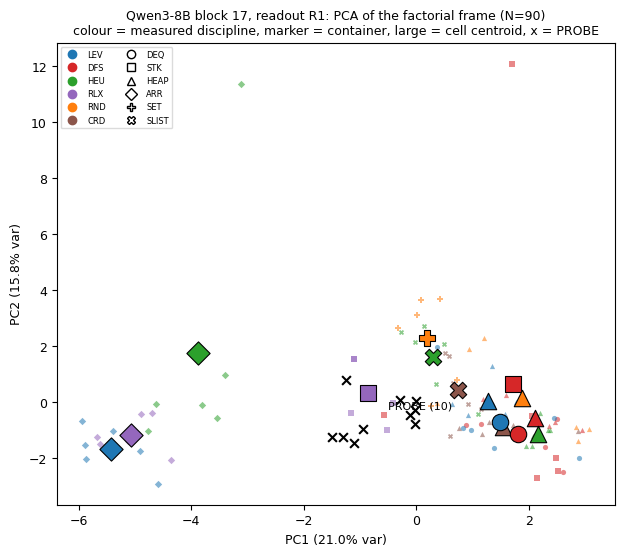

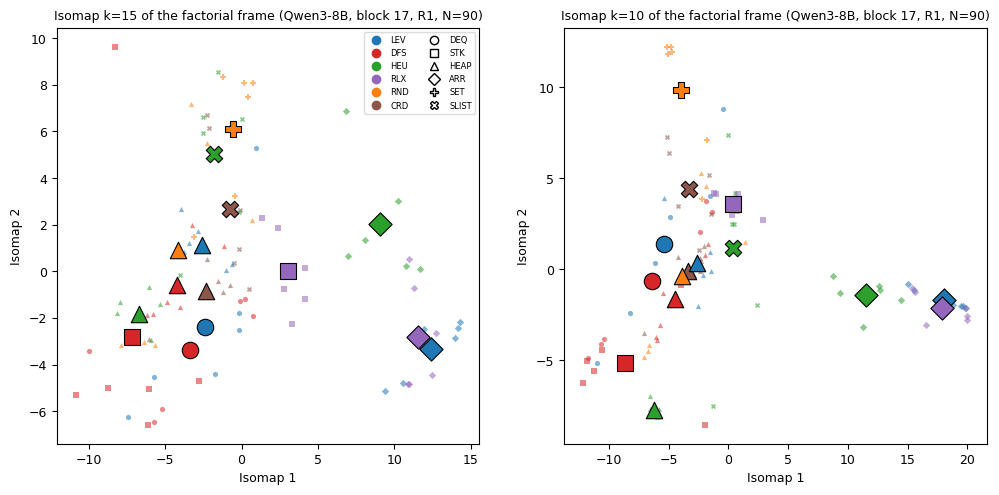

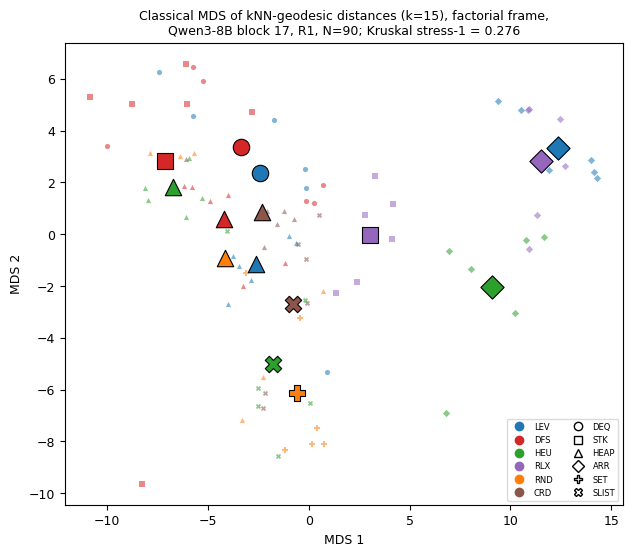

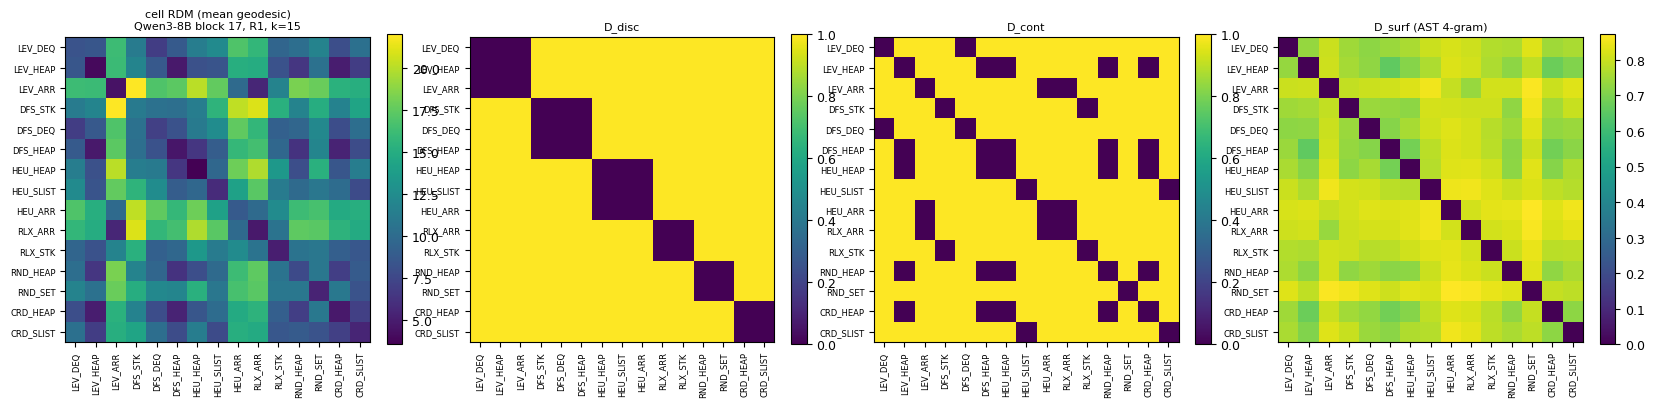

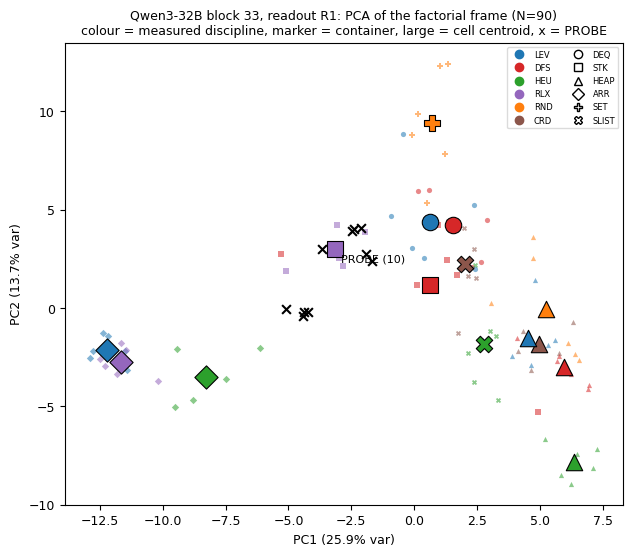

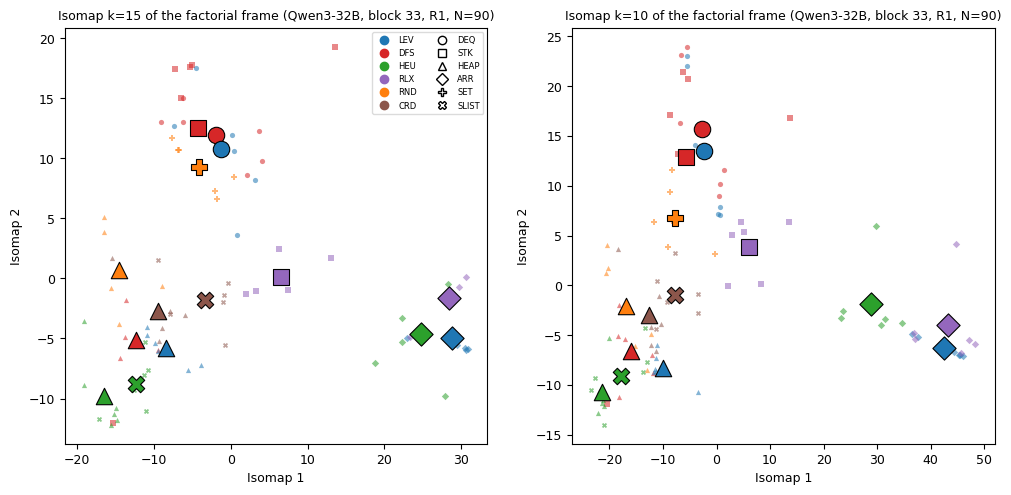

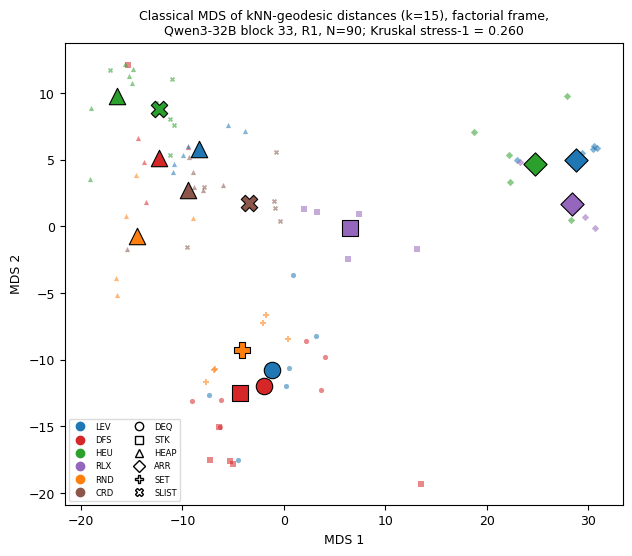

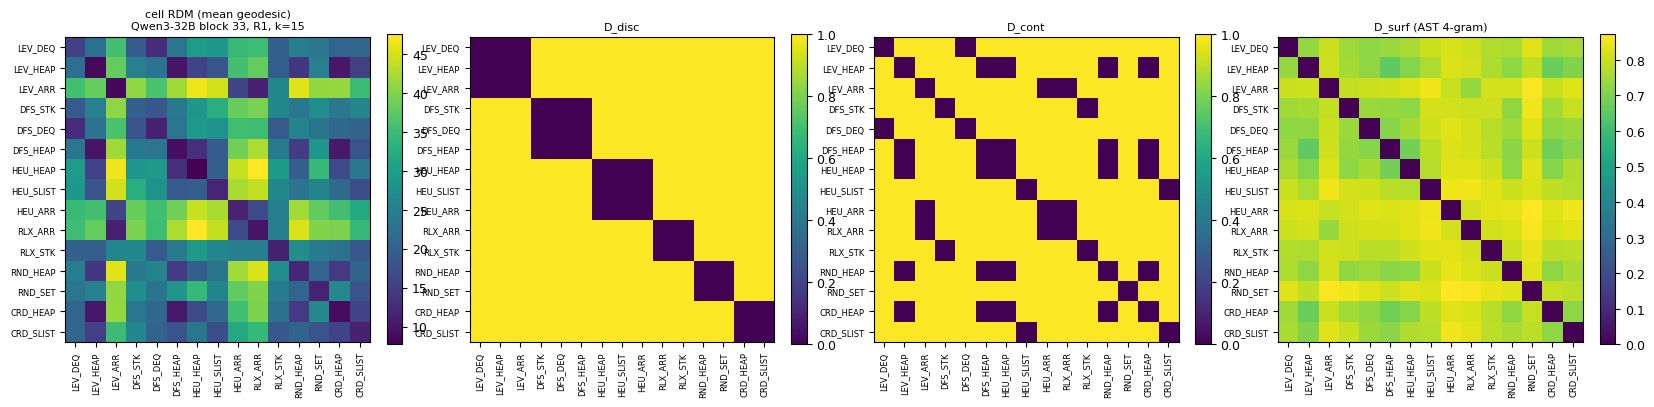

In [22]:
for tag in MODELS:
    per_model(tag)

## Results: demo vs full run

The forest plot is `figures.py::forest`. For each model it shows $\rho_d$ (discipline | container) and $\rho_c$ (container | discipline):
- dots with bootstrap 95% CIs;
- a grey band for the 2.5–97.5 % range of the restricted-permutation null;
- squares for the $\rho_d$ of the three lexical baselines;
- an orange dotted line for the noise ceiling;
- the preregistered thresholds 0.1 and 0.3 as black lines.

The table puts the demo numbers next to the full-run numbers stored in `mini_demo_data.json`. The demo uses 90 instead of 221 programs, a placement frame without the F0 catalogue, and 10 instead of 16 PROBE programs, so individual values move. These patterns should hold:
- $\rho_c \gg \rho_d$;
- surface + length carry most of the unique variance while discipline carries ~0;
- the PROBE programs land with the relaxation *surface* (RLX cells), not at their measured LEV_DEQ behaviour;
- most LOO errors stay inside the container.

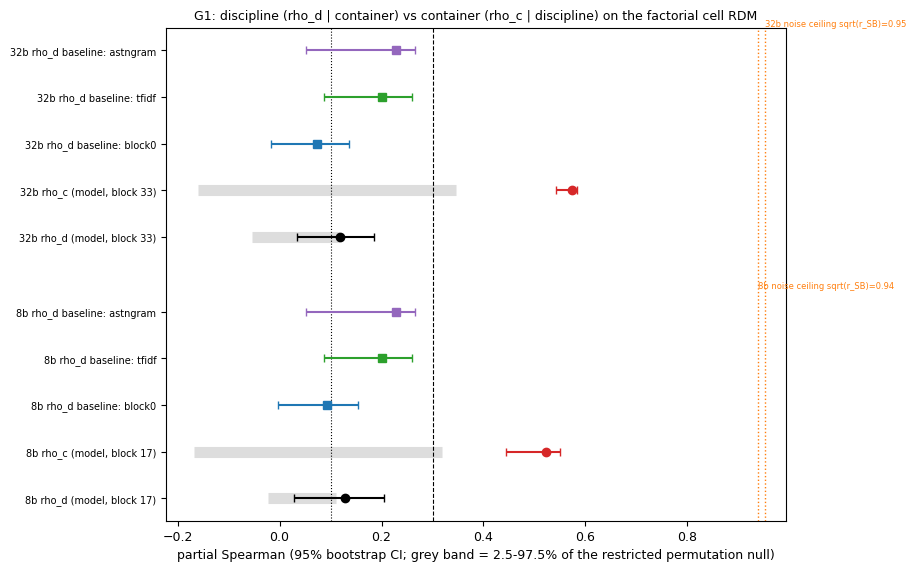

model  statistic                                     demo                   full run (221 programs)
-----  --------------------------------------------  ---------------------  -----------------------
8b     programs in the G1 frame                      90                     221                    
8b     rho_d = pSpearman(D, D_disc | D_cont)         0.129                  0.104                  
8b     rho_c = pSpearman(D, D_cont | D_disc)         0.523                  0.462                  
8b     rho_d_full (+ surface, length, dispersion)    0.129                  0.028                  
8b     exact within-container p(rho_d)               0.005                  0.053                  
8b     exact within-discipline p(rho_c)              0.001                  0.002                  
8b     bootstrap 95% CI of rho_d (B = 1000 / 1000)   0.028 / 0.204          0.026 / 0.137          
8b     P_boot(rho_d > rho_c)                         0.000                  0.000                  


In [23]:
def forest() -> None:
    rows = []
    for tag in ("8b", "32b"):
        if tag in G1:                                  # original: read results/g1_<model>.json if it exists
            rows.append((tag, G1[tag]))
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(8, 1.2 + 1.3 * len(rows) * 2))
    y = 0
    yt, yl = [], []
    for tag, g in rows:
        nc = g["noise_ceiling"]
        for stat in ("rho_d", "rho_c"):
            pt = g["point_model"][stat]
            ci = g["bootstrap"]["model"][stat]["ci95"]
            nq = g["perm"]["model"][stat]["null_q"]
            ax.plot([nq[0], nq[3]], [y, y], color="#dddddd", lw=8, solid_capstyle="butt", zorder=1)
            # error lengths clipped at 0: with a small demo bootstrap the point can fall outside its CI
            ax.errorbar(pt, y, xerr=[[max(0.0, pt - ci[0])], [max(0.0, ci[1] - pt)]], fmt="o",
                        color="k" if stat == "rho_d" else "#d62728", capsize=3, zorder=3)
            yt.append(y)
            yl.append(f"{tag} {stat} (model, block {g['block']})")
            y += 1
        for b, colr in (("block0", "#1f77b4"), ("tfidf", "#2ca02c"), ("astngram", "#9467bd")):
            pt = g["point_" + b]["rho_d"]
            ci = g["bootstrap"][b]["rho_d"]["ci95"]
            ax.errorbar(pt, y, xerr=[[max(0.0, pt - ci[0])], [max(0.0, ci[1] - pt)]], fmt="s", color=colr, capsize=3,
                        zorder=3)
            yt.append(y)
            yl.append(f"{tag} rho_d baseline: {b}")
            y += 1
        ax.axvline(nc["ceiling_sqrt"], color="#ff7f0e", ls=":", lw=1)
        ax.text(nc["ceiling_sqrt"], y - 0.5, f"{tag} noise ceiling sqrt(r_SB)={nc['ceiling_sqrt']:.2f}", fontsize=6,
                color="#ff7f0e")
        y += 0.6
    ax.axvline(0.3, color="k", ls="--", lw=0.8)
    ax.axvline(0.1, color="k", ls=":", lw=0.8)
    ax.set_yticks(yt, yl, fontsize=7)
    ax.set_xlabel("partial Spearman (95% bootstrap CI; grey band = 2.5-97.5% of the restricted permutation null)")
    ax.set_title("G1: discipline (rho_d | container) vs container (rho_c | discipline) on the factorial cell RDM", fontsize=9)
    save(fig, "g1_forest")


forest()

# ---------------------------------------------------------------------------------------------- demo vs full run
REF = data["metadata"]["full_run_reference"]


def fmt(x: Any) -> str:
    if isinstance(x, float):
        return f"{x:.3f}"
    if isinstance(x, (list, tuple)):
        return " / ".join(fmt(v) for v in x)
    if isinstance(x, dict):
        return ", ".join(f"{k} {v}" for k, v in sorted(x.items(), key=lambda kv: -kv[1]))
    return str(x)


lines = [("model", "statistic", "demo", "full run (221 programs)")]
for tag in MODELS:
    g, r, v = G1[tag], REF[tag], ver["g1"][tag]
    pr = G2P[(tag, K_PRIMARY)]["probe"]
    key = f"predict_nearest_cell_{tag}"
    c, rc = conf_out[key], REF["loo_confusion"][key]
    table = [
        ("programs in the G1 frame", g["n_programs"], r["n_programs"]),
        ("rho_d = pSpearman(D, D_disc | D_cont)", g["point_model"]["rho_d"], r["rho_d"]),
        ("rho_c = pSpearman(D, D_cont | D_disc)", g["point_model"]["rho_c"], r["rho_c"]),
        ("rho_d_full (+ surface, length, dispersion)", g["point_model"]["rho_d_full"], r["rho_d_full"]),
        ("exact within-container p(rho_d)", g["perm"]["model"]["rho_d"]["p_greater"], r["p_rho_d"]),
        ("exact within-discipline p(rho_c)", g["perm"]["model"]["rho_c"]["p_greater"], r["p_rho_c"]),
        (f"bootstrap 95% CI of rho_d (B = {g['bootstrap']['B']} / {r['bootstrap_B']})",
         g["bootstrap"]["model"]["rho_d"]["ci95"], r["boot_ci95_rho_d"]),
        ("P_boot(rho_d > rho_c)", g["bootstrap"]["model_rho_d_minus_rho_c"]["P_rho_d_gt_rho_c"], r["P_boot_rho_d_gt_rho_c"]),
        ("noise ceiling (Spearman-Brown)", g["noise_ceiling"]["spearman_brown"], r["noise_ceiling"]["spearman_brown"]),
        ("rho_d of block0 / tfidf / astngram", [g[f"point_{b}"]["rho_d"] for b in ("block0", "tfidf", "astngram")],
         [r["baselines_rho_d"][b] for b in ("block0", "tfidf", "astngram")]),
        ("unique R2: disc / cont / surface+length", [g["commonality"][f"unique_{k}"] for k in ("disc", "cont", "surf_len")],
         [r["commonality"][f"unique_{k}"] for k in ("disc", "cont", "surf_len")]),
        ("G1 verdict (fragile)", f"{v['verdict']} ({v['fragile']})", f"{r['verdict']['verdict']} ({r['verdict']['fragile']})"),
        ("LOO nearest-cell acc.: cell / disc / cont", [loo_acc[tag][k] for k in ("cell", "discipline", "container")],
         [r["loo_accuracy"][k] for k in ("cell", "discipline", "container")]),
        ("LOO errors: same-container / same-disc / all",
         f"{c['same_container_other_discipline']} / {c['same_discipline_other_container']} / {c['errors']}",
         f"{rc['same_container_other_discipline']} / {rc['same_discipline_other_container']} / {rc['errors']}"),
        ("PROBE programs' nearest cell (k = 15)", pr["nearest_cell_counts"], r["probe_nearest_cell_counts_F1"]),
    ]
    lines += [(tag, name, fmt(a), fmt(b)) for name, a, b in table]
w = [max(len(x[i]) for x in lines) for i in range(4)]
for i, x in enumerate(lines):
    print("  ".join(s.ljust(w[j]) for j, s in enumerate(x)))
    if i == 0:
        print("  ".join("-" * n for n in w))
print(f"\nclaim G1 -- demo: {ver['g1']['claim_G1']} | full run: {REF['claim_G1']}")